# Exploratory Data Analysis (EDA)

## 0. Introduction

This notebook contains the exploratory data analysis (EDA) of the **C-MAPSS** dataset (Commercial Modular Aero-Propulsion System Simulation), a NASA dataset widely used to develop and benchmark **Remaining Useful Life (RUL)** prediction models for turbofan engines.

The dataset contains multivariate run-to-failure time series: each engine (unit) starts in a healthy state and is simulated until failure, recording, at every cycle, a set of operational settings and 21 sensor measurements.

The goal of this phase is to explore the structure, patterns, characteristics and anomalies of the data, and to formulate and verify hypotheses about it, before moving on to feature engineering and modeling.

## 1. Import Libraries

In [35]:
import sys
sys.path.append("../src")

import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import the modules (not only their functions) so that they can be reloaded
import utils
import eda_utils
import data_loader

# Reload in dependency order: utils first, since eda_utils imports it
importlib.reload(utils)
importlib.reload(eda_utils)
importlib.reload(data_loader)

# Re-bind the names to the reloaded functions
from data_loader import txt_to_csv
from utils import save_figure
from eda_utils import (
    dataset_summary,
    count_units,
    cycles_per_unit,
    missing_values,
    plot_multiple_sensor_evolution,
    rolling_mean,
    rolling_std,
    plot_sensor_dendrogram,
    plot_sensor_by_operating_condition,
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 2. Load the Dataset

The dataset has already been downloaded; the important step is to convert it into `.csv` format, assigning the column names. According to the dataset documentation, the features are, in this order:

    - unit number (engine id)
    - cycle (engine cycle number)
    - operational setting 1
    - operational setting 2 (these 3 features together give a total of 6 operating conditions)
    - operational setting 3
    - sensor1, sensor2, ..., sensor21

For each engine, data are available up to failure, so the RUL of each engine is:

$$
RUL(t) = maxCycle - cycle(t)
$$

In [36]:
column_names = [
    "unit number",
    "cycle",
    "operational setting 1",
    "operational setting 2",
    "operational setting 3",
] + [f"sensor{i}" for i in range(1, 22)]

txt_to_csv("train_FD004.txt", "train.csv", column_names)
txt_to_csv("test_FD004.txt", "test.csv", column_names)
txt_to_csv("RUL_FD004.txt", "target_test.csv", ["RUL"])

dataset = pd.read_csv("../data/csv/train.csv", sep=",")

File created: data/csv/train.csv (61249 rows written)
File created: data/csv/test.csv (41214 rows written)
File created: data/csv/target_test.csv (248 rows written)


## 3. Dataset Description

In [37]:
summary = dataset_summary(dataset)

Dataset shape:
(61249, 26)

Dataset dtypes:
unit number                int64
cycle                      int64
operational setting 1    float64
operational setting 2    float64
operational setting 3    float64
sensor1                  float64
sensor2                  float64
sensor3                  float64
sensor4                  float64
sensor5                  float64
sensor6                  float64
sensor7                  float64
sensor8                  float64
sensor9                  float64
sensor10                 float64
sensor11                 float64
sensor12                 float64
sensor13                 float64
sensor14                 float64
sensor15                 float64
sensor16                 float64
sensor17                   int64
sensor18                   int64
sensor19                 float64
sensor20                 float64
sensor21                 float64
dtype: object

Dataset statistics:
        unit number         cycle  operational setting 1  \
cou

The dataset therefore has 26 total features and 61249 rows; all 26 features are numeric, so there are no categorical or other types of features.

In [38]:
n_missing = missing_values(dataset)
print(n_missing)

unit number              0
cycle                    0
operational setting 1    0
operational setting 2    0
operational setting 3    0
sensor1                  0
sensor2                  0
sensor3                  0
sensor4                  0
sensor5                  0
sensor6                  0
sensor7                  0
sensor8                  0
sensor9                  0
sensor10                 0
sensor11                 0
sensor12                 0
sensor13                 0
sensor14                 0
sensor15                 0
sensor16                 0
sensor17                 0
sensor18                 0
sensor19                 0
sensor20                 0
sensor21                 0
dtype: int64


The dataset therefore has no missing values to handle.

## 4. Cycles per Engine

We look at the distribution of the total lifetime (in cycles) of each engine.

Figure saved to: figures/cycles_distribution.png


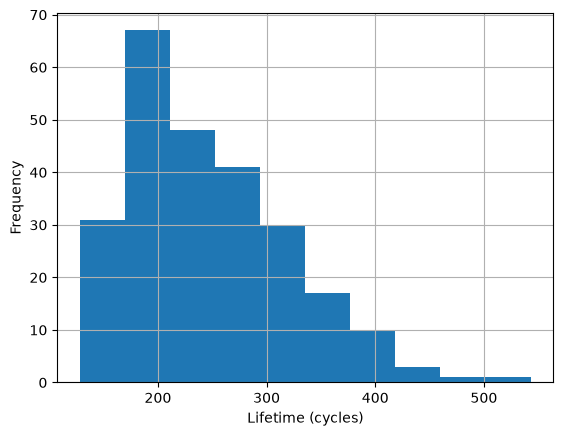

In [39]:
cycles = cycles_per_unit(dataset)

cycles.hist()
plt.xlabel("Lifetime (cycles)")
plt.ylabel("Frequency")
save_figure(plt.gcf(), "cycles_distribution")

plt.show()

This distribution is very asymmetric: most engines have a lifetime of about 200 cycles, while only a few reach more than 450 cycles.

## 5. Sensors

We now look at the statistical characteristics of the sensors.

### 5.1 Variance

In [40]:
dataset.var().sort_values()

sensor16                      0.000022
sensor10                      0.016302
operational setting 2         0.096537
sensor15                      0.563061
sensor11                     10.520237
sensor5                      13.125202
sensor19                     28.830710
sensor6                      29.637316
sensor21                     35.553759
sensor20                     98.731968
operational setting 3       203.118191
operational setting 1       218.469733
sensor1                     698.906067
sensor17                    773.300629
sensor2                    1394.473263
unit number                5183.330401
sensor14                   7339.442015
cycle                      8061.057015
sensor3                   11271.558809
sensor4                   14239.073899
sensor13                  16434.691116
sensor12                  19176.463675
sensor8                   21126.111710
sensor18                  21162.245693
sensor7                   21573.795950
sensor9                  

### 5.2 Number of Possible Values

In [41]:
dataset.nunique()

unit number                249
cycle                      543
operational setting 1      536
operational setting 2      105
operational setting 3        2
sensor1                      6
sensor2                   1704
sensor3                  13558
sensor4                  17353
sensor5                      6
sensor6                     46
sensor7                   5926
sensor8                   1038
sensor9                  25297
sensor10                    21
sensor11                   737
sensor12                  5627
sensor13                   483
sensor14                 15938
sensor15                 11915
sensor16                     2
sensor17                    54
sensor18                     6
sensor19                     2
sensor20                   652
sensor21                 21574
dtype: int64

We note that sensor16 has an almost null variance (about 0.00002) and only 2 possible values; in the feature-selection phase we might consider removing it.

### 5.3 Sensor Evolution over Time

We now plot the evolution of every sensor for a given engine. It is likely that, as the number of lifecycle cycles increases, some sensors show a positive or negative trend, which could be an indicator of engine degradation: we test this on the engine identified by unit number = 4.

Figure saved to: figures/4_evolution.png


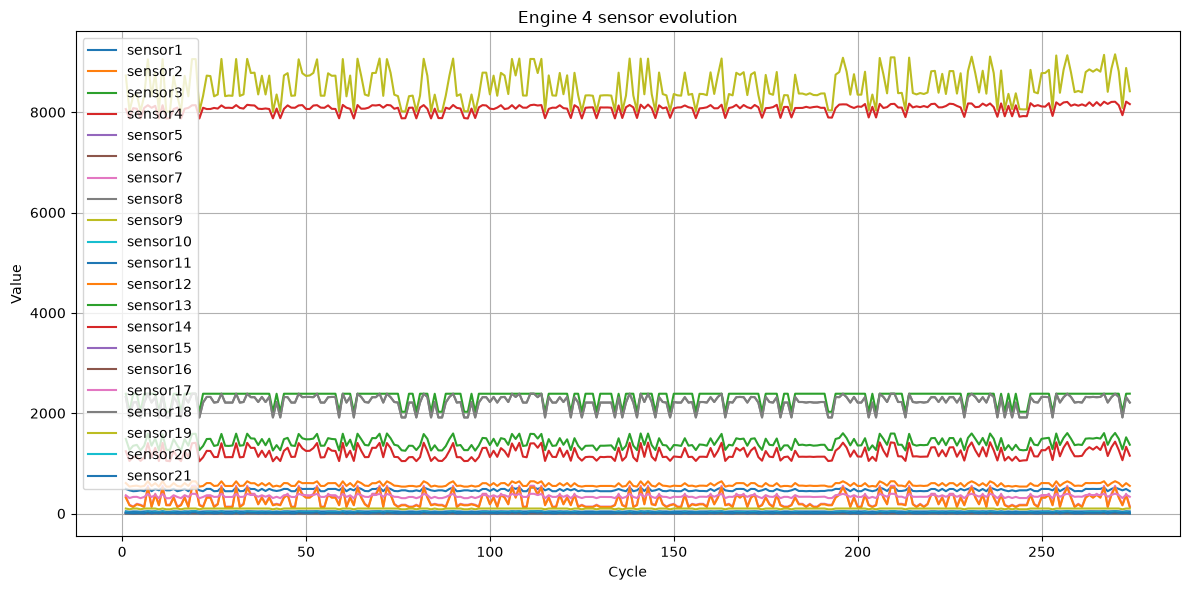

In [42]:
unit_number = 4

fig_sensor_evolution = plot_multiple_sensor_evolution(
    dataset, unit_number, [f"sensor{i}" for i in range(1, 22)], save=True
)

The sensors are obviously very noisy, so it is not possible to visually recognize degradation-related patterns for a single engine; and even if it were, visually inspecting every chart would not be a scalable approach.

### 5.4 Rolling Mean

To reduce noise, we can introduce a rolling mean with a window size w for the i-th engine, given by

$$
\bar{x}_t = \frac{1}{w}\sum_{i=0}^{w-1} x_{t-i}
$$

This method involves a trade-off:

    - small window: more detail but also more noise
    - large window: less noise but also less detail on the variations

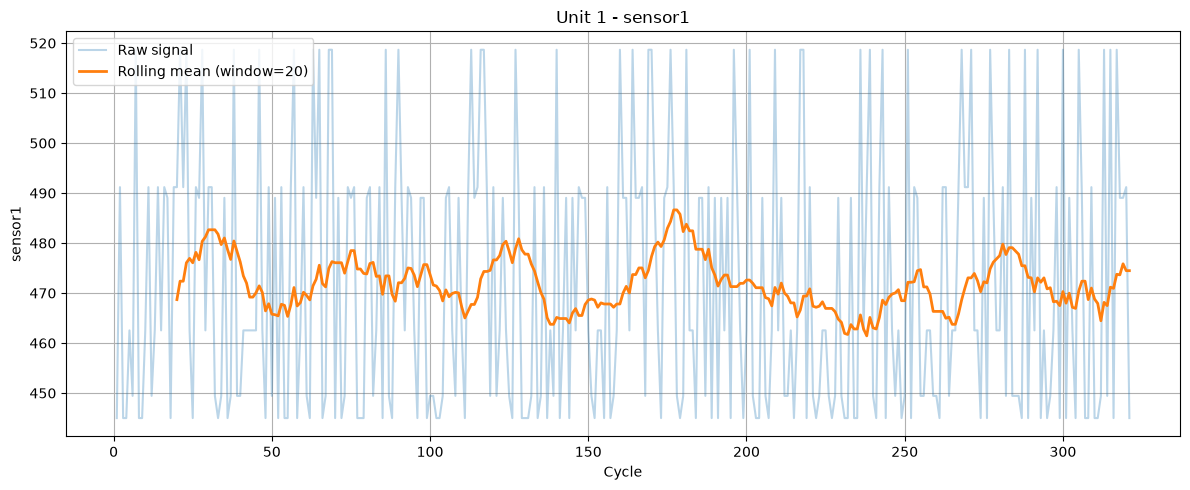

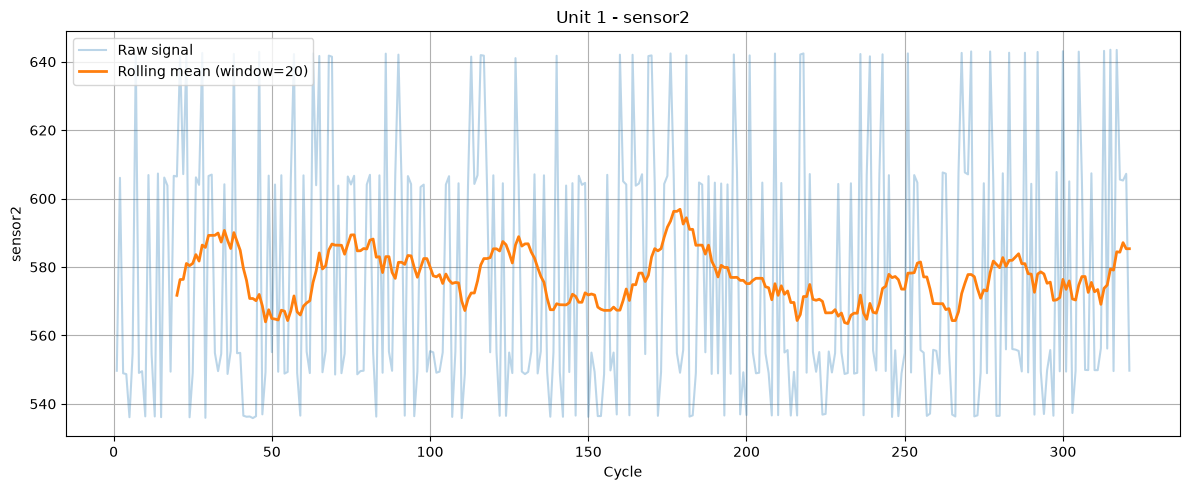

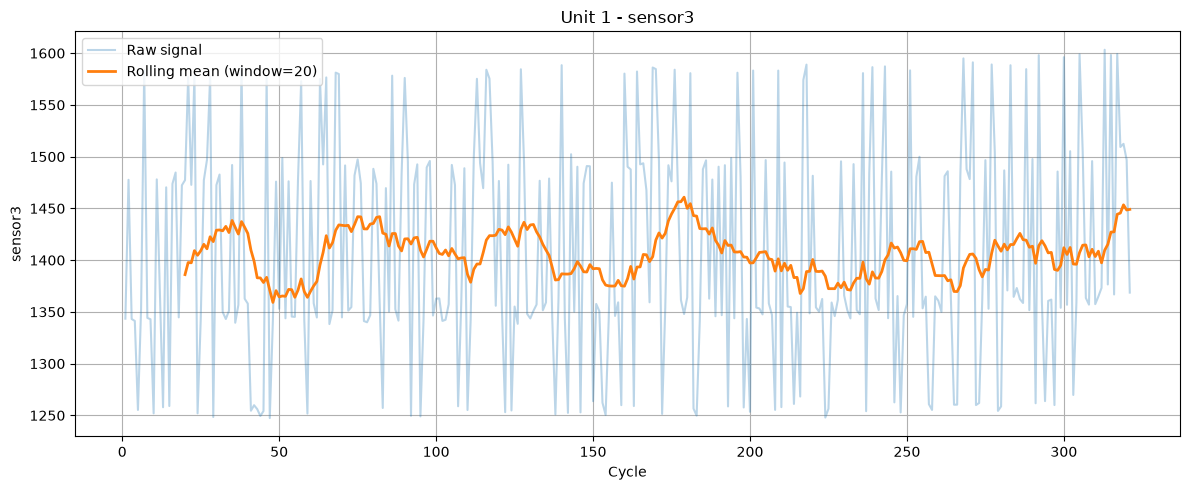

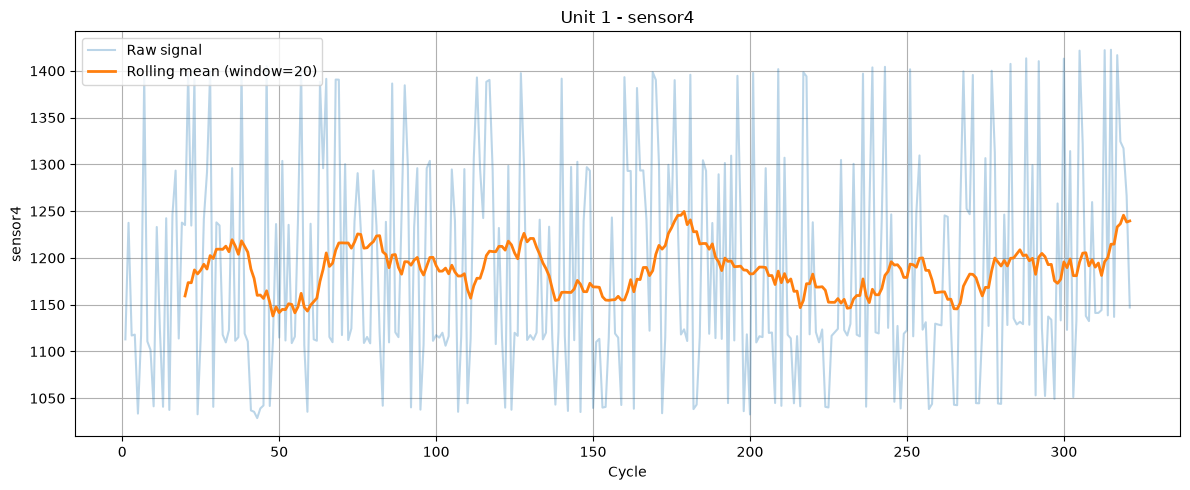

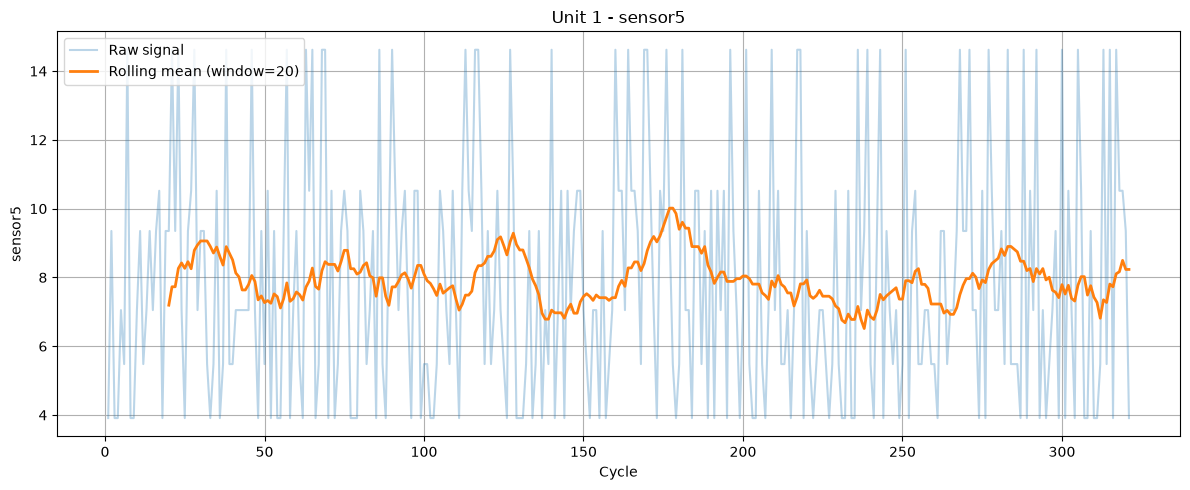

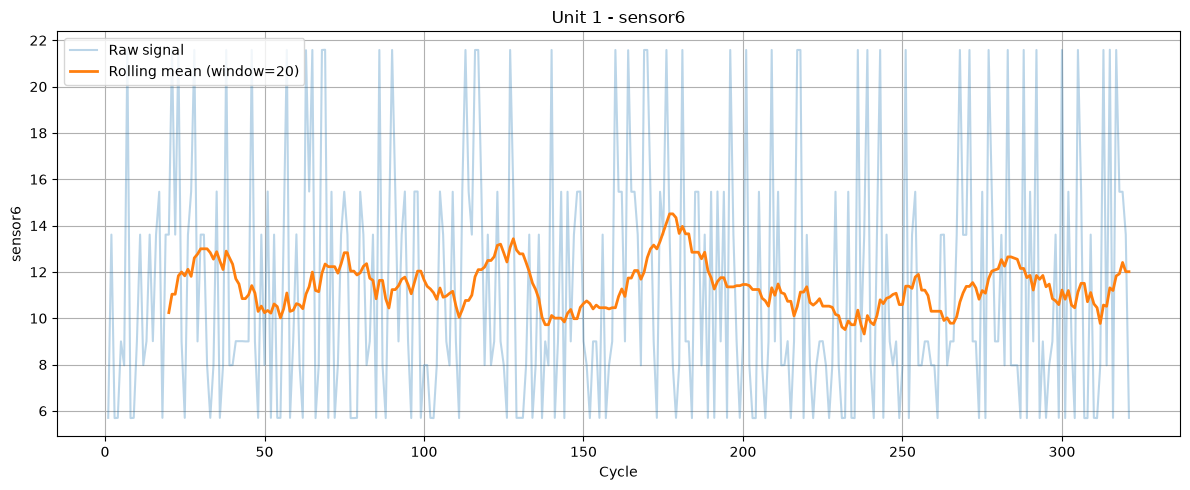

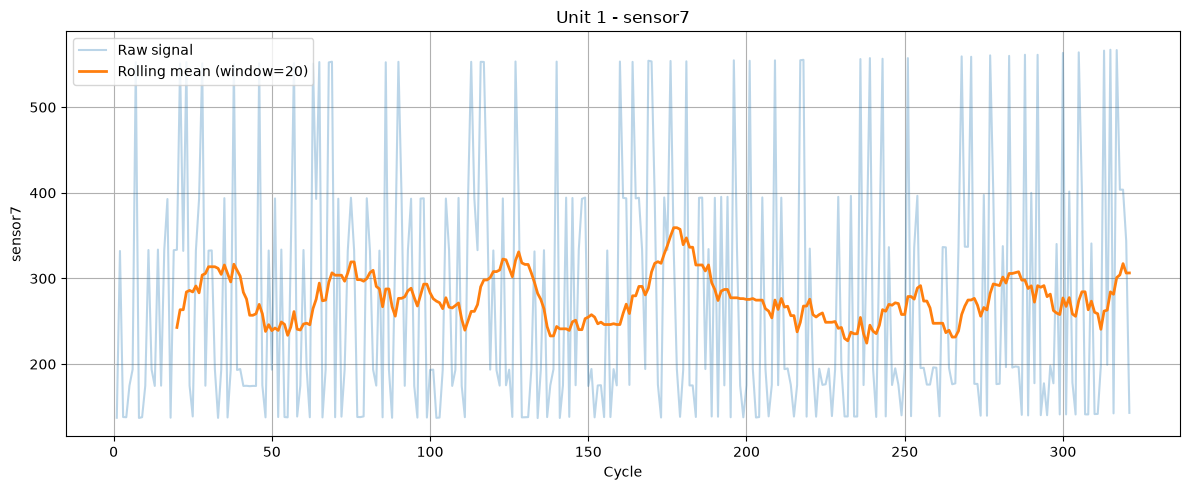

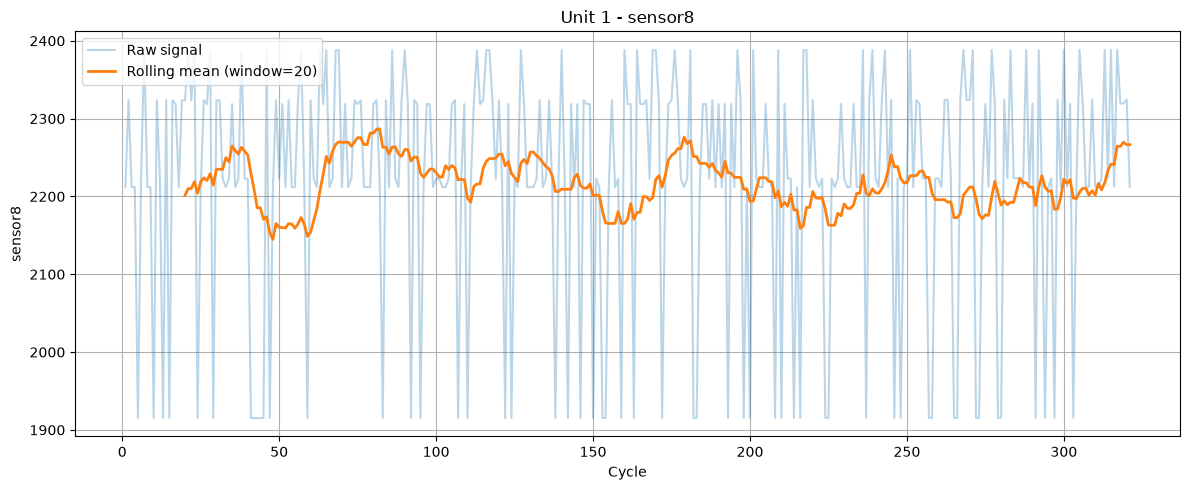

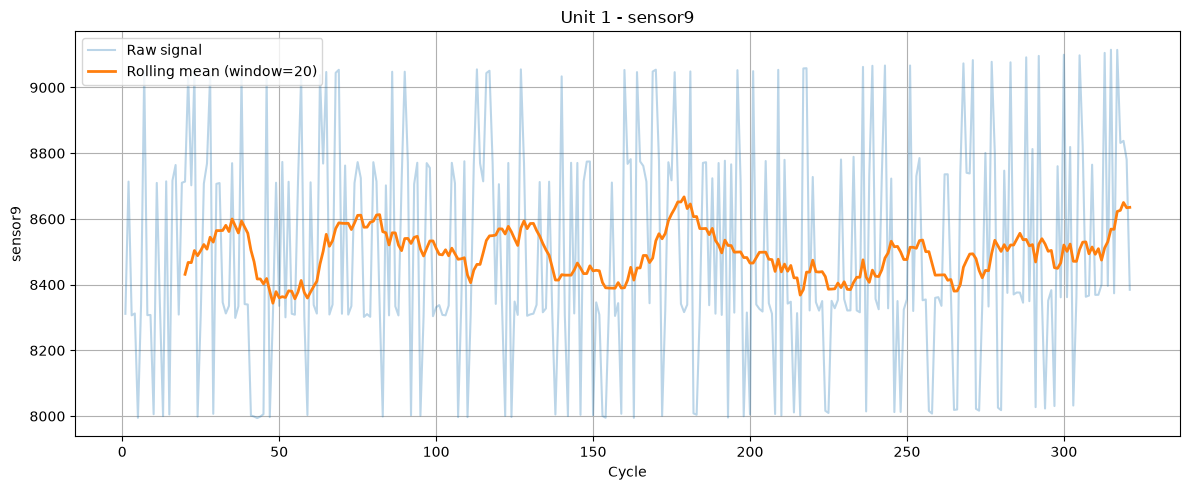

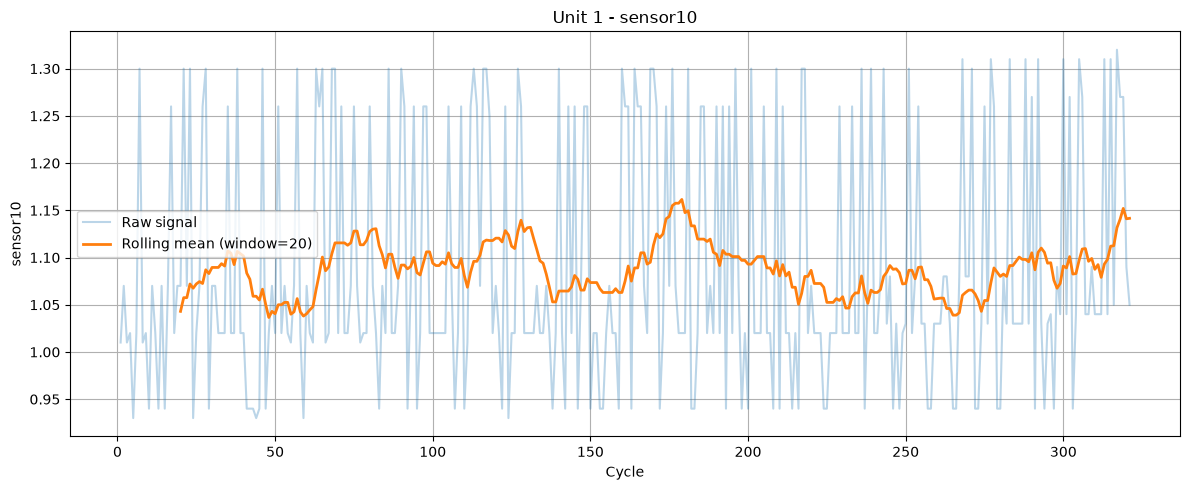

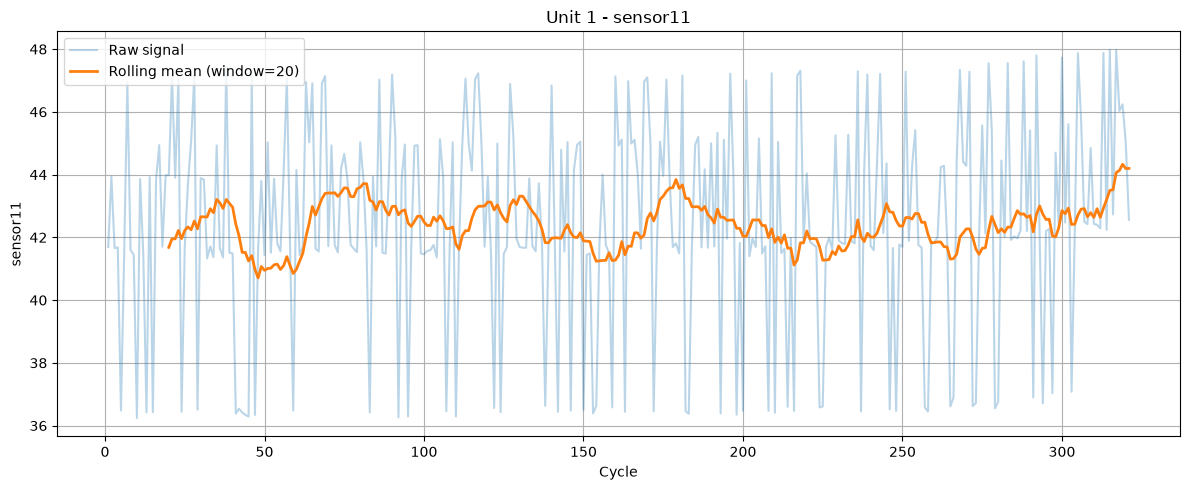

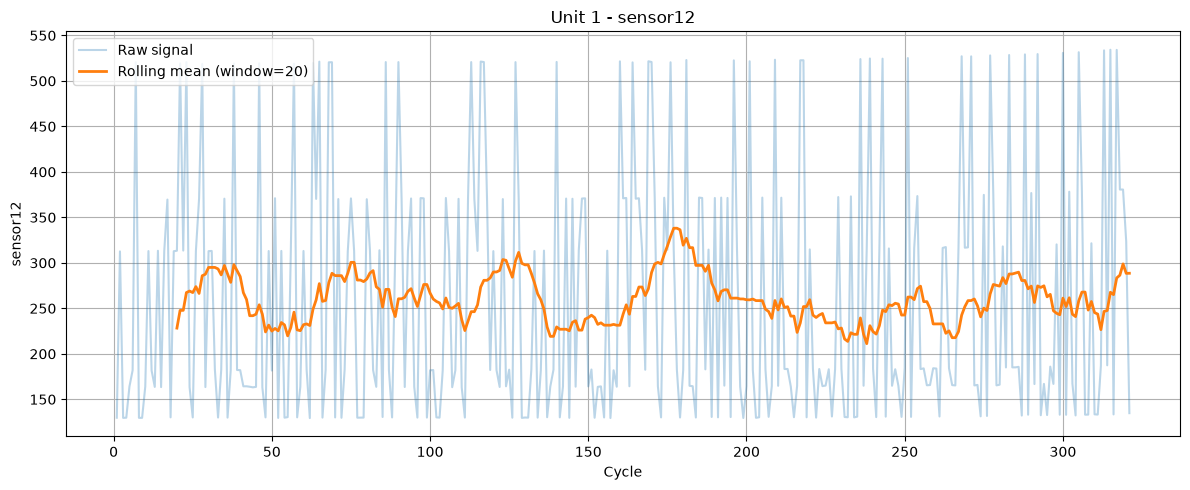

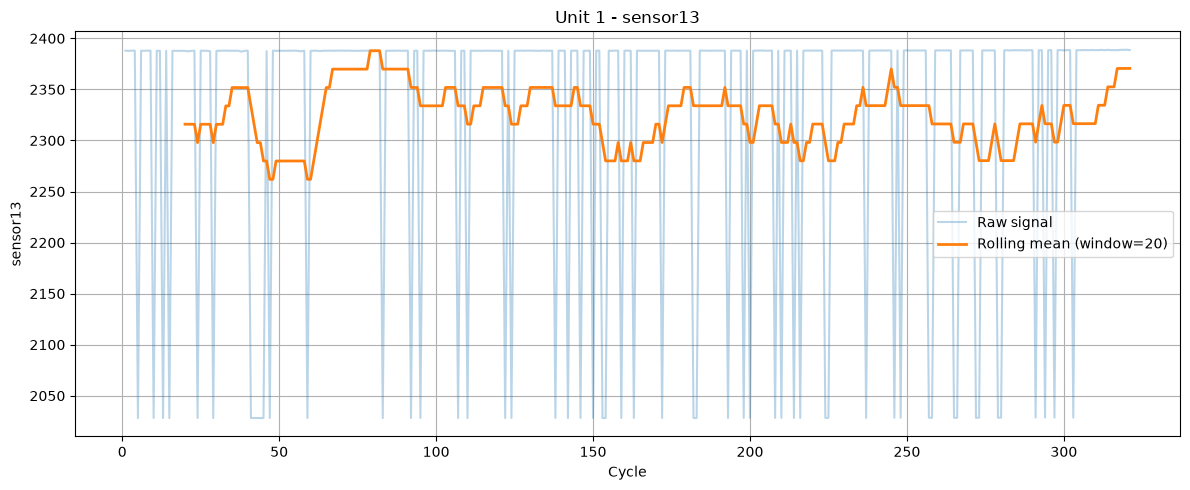

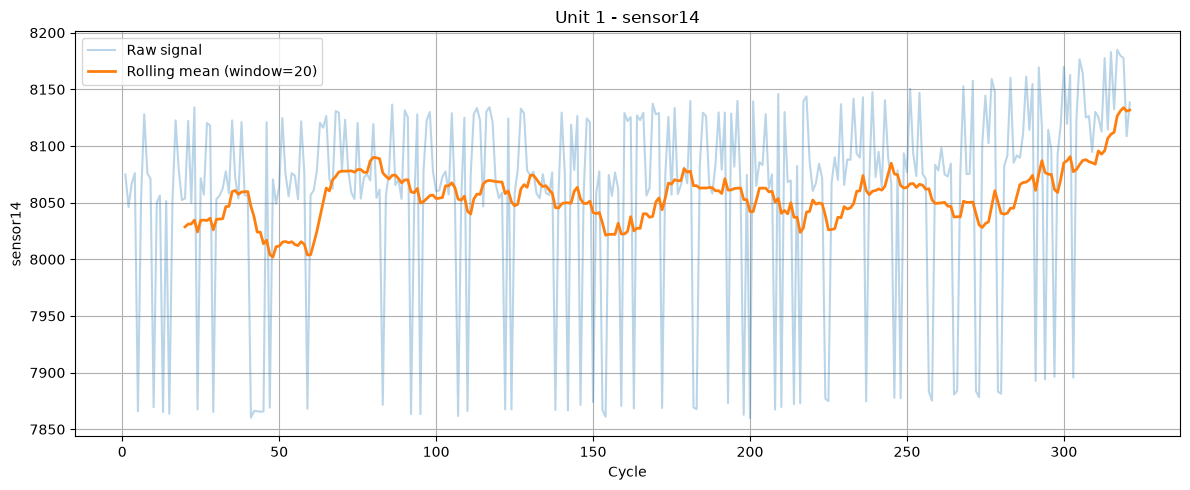

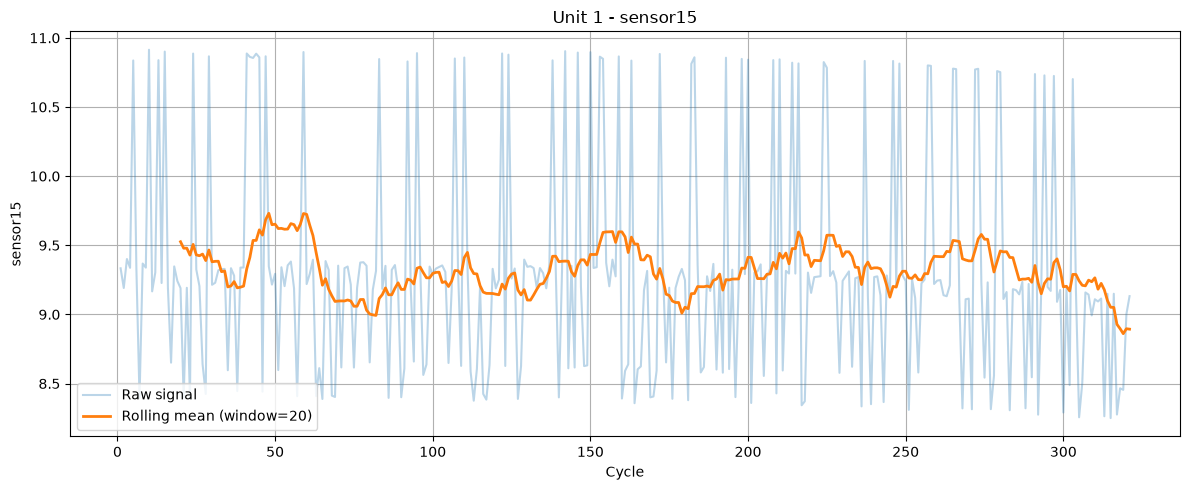

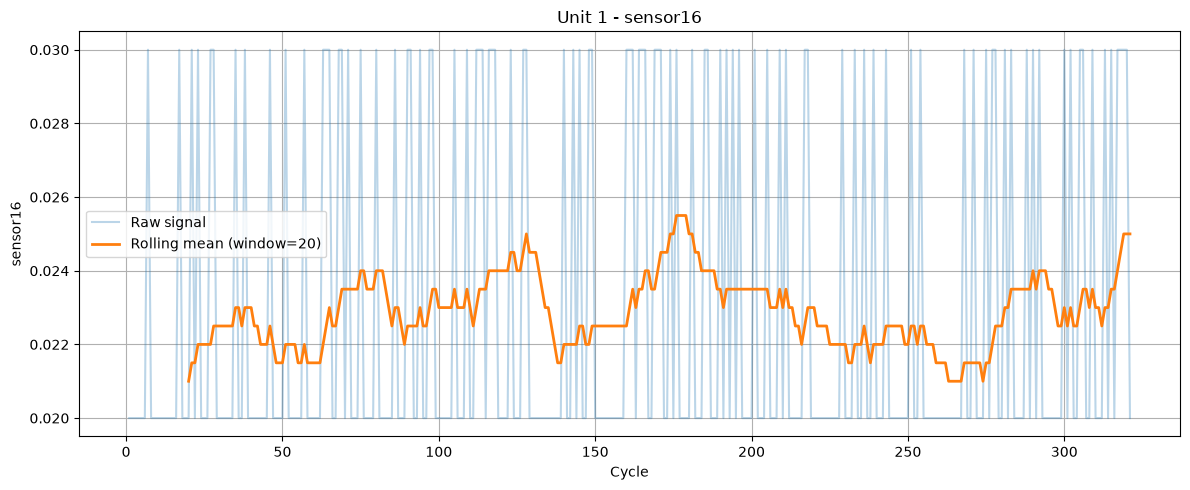

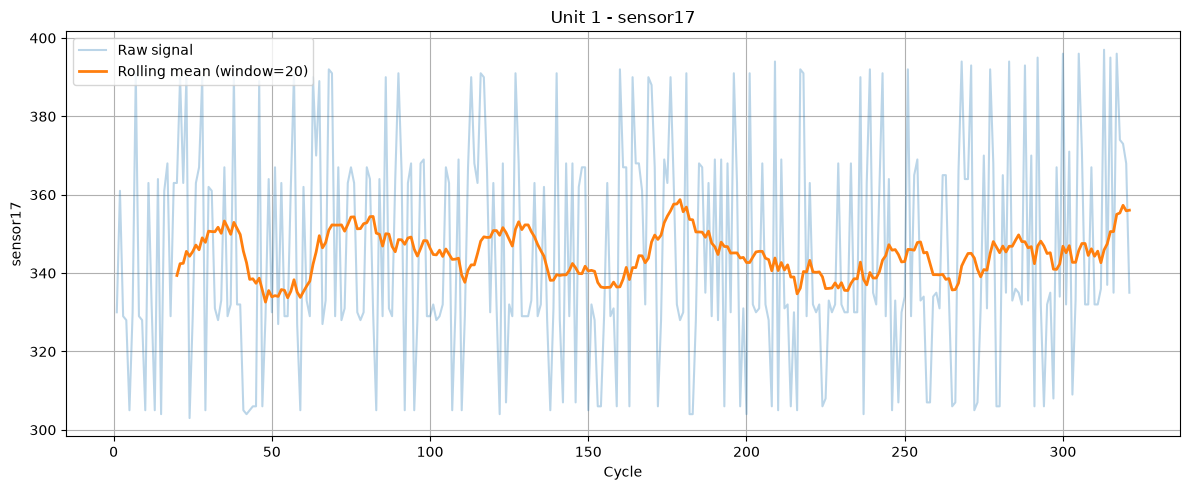

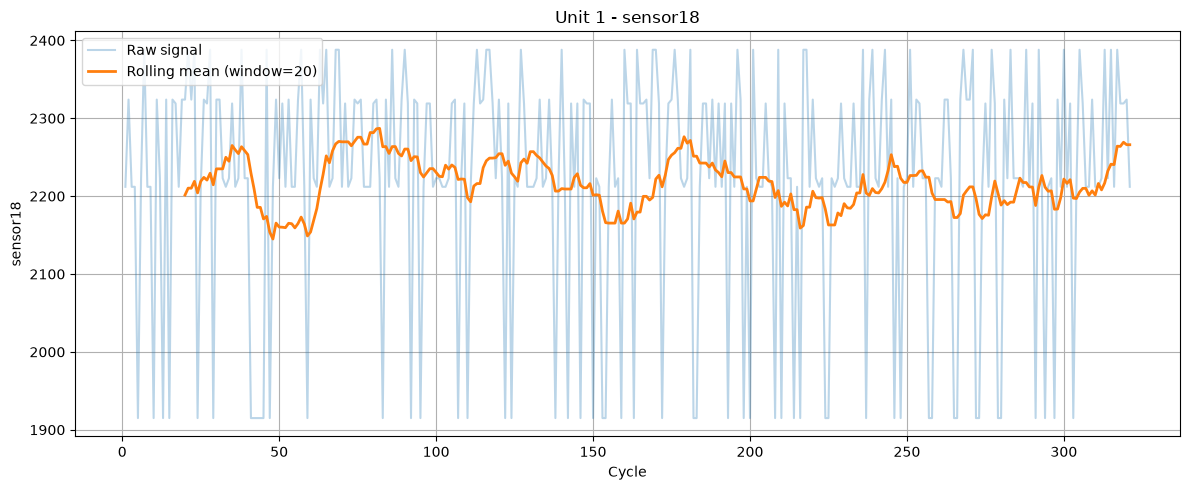

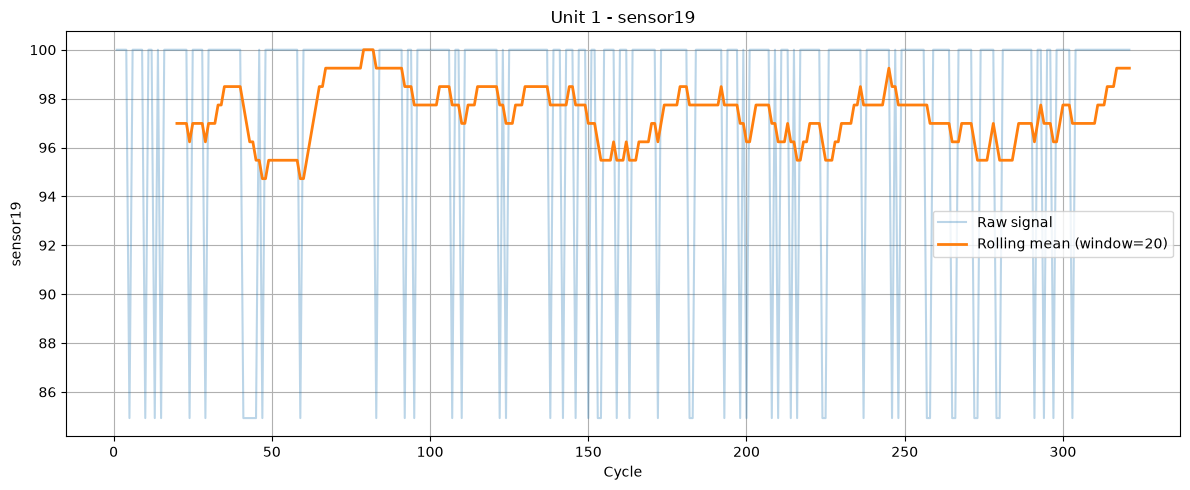

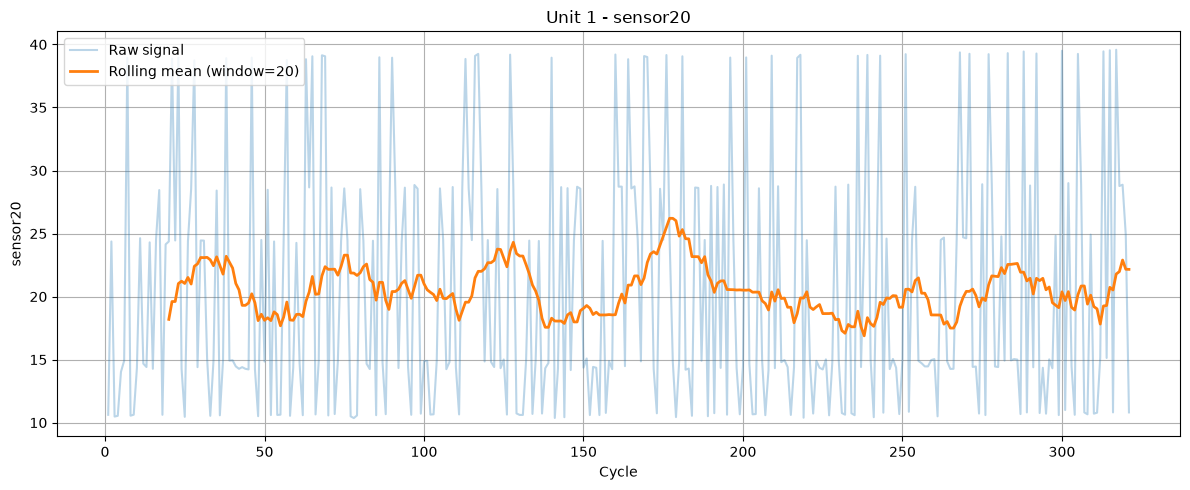

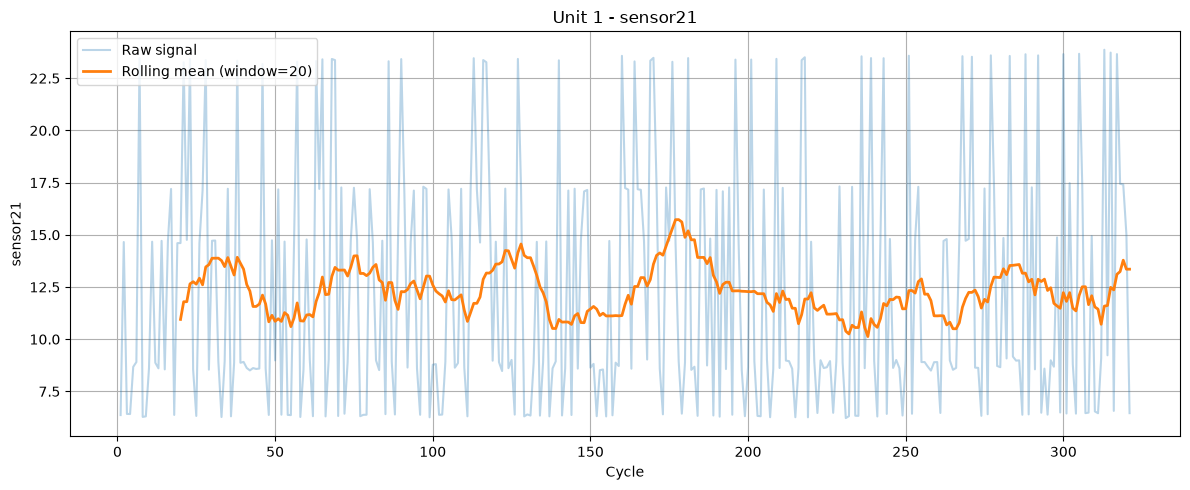

In [43]:
for i in range(1, 22):
    rolling_mean(dataset, 1, f"sensor{i}")

For this engine it is possible to observe that, during the final part of its lifecycle, sensor14 shows an increasing trend while sensor15 shows a decreasing trend. This behavior suggests a possible relationship between the temporal evolution of these signals and the engine's degradation state.

However, when looking at trajectories of other engines, this behavior is not always evident. This variability may be due both to different degradation modes across engines and to the influence of the different operating conditions on the sensor response. This observation therefore represents an exploratory hypothesis, which will need to be verified through a quantitative analysis on a larger set of engines and by building more robust temporal features.

### 5.5 Rolling Standard Deviation

In addition to the rolling mean, the rolling standard deviation can highlight changes in a signal's variability over time, which can also be informative of degradation.

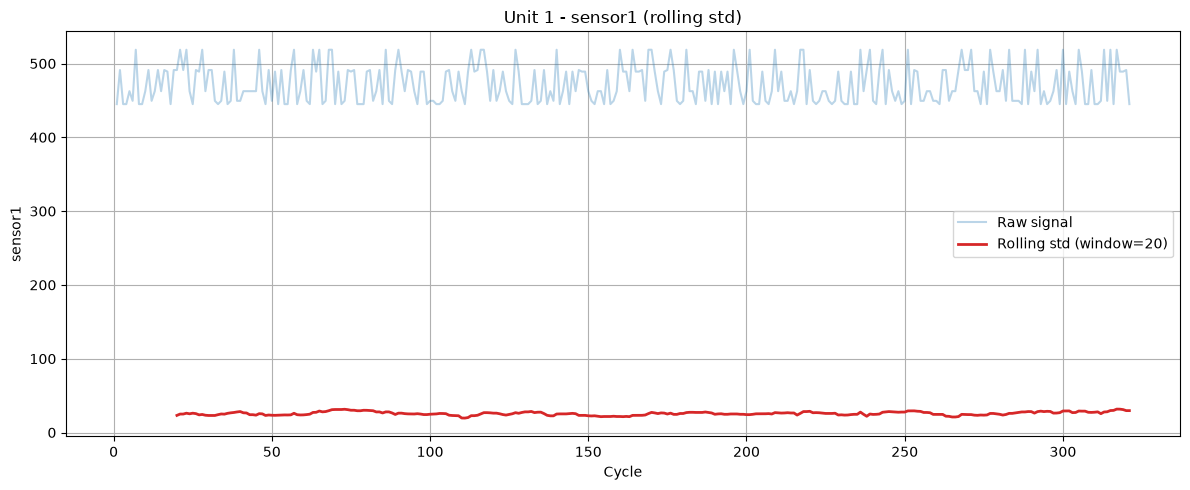

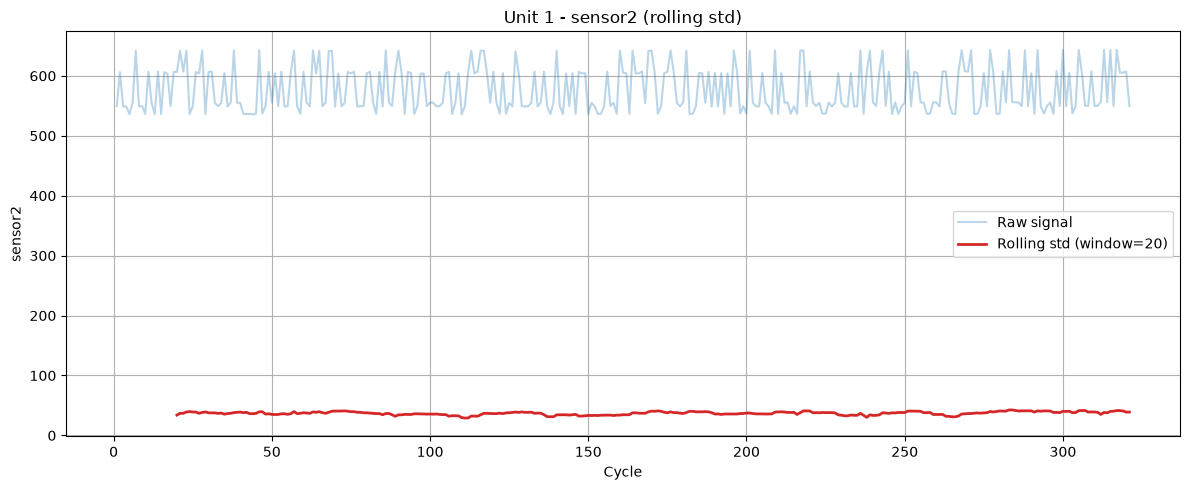

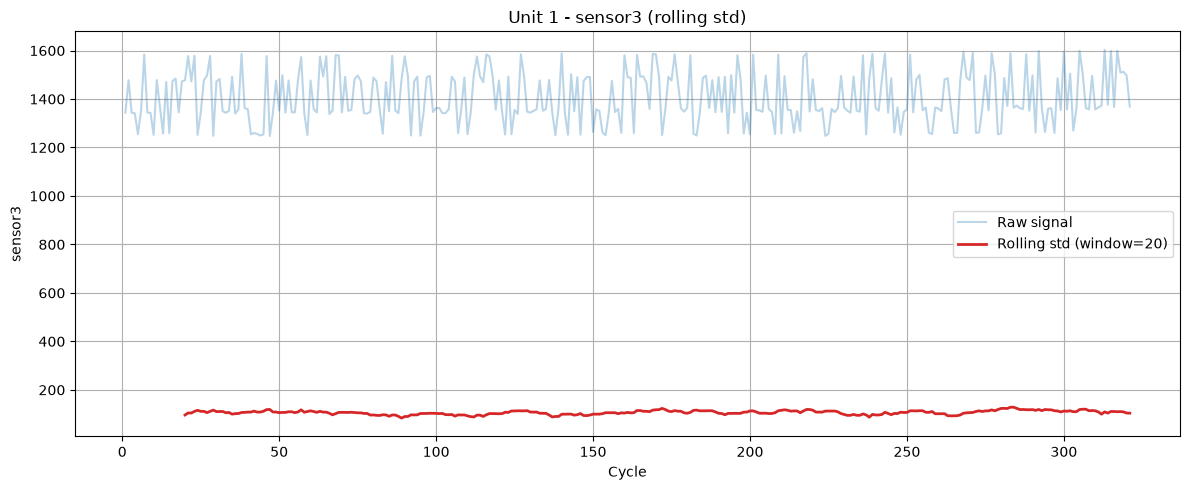

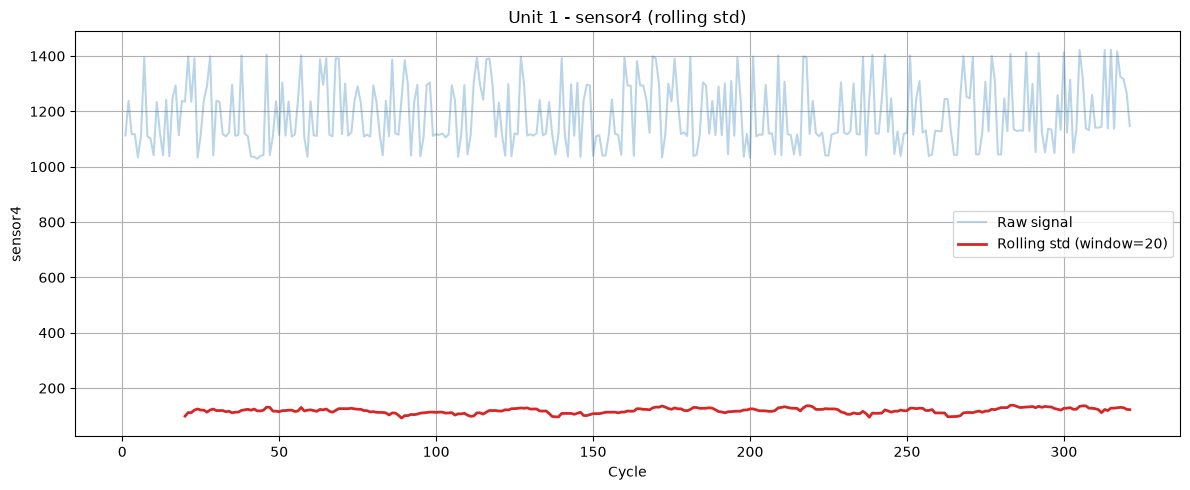

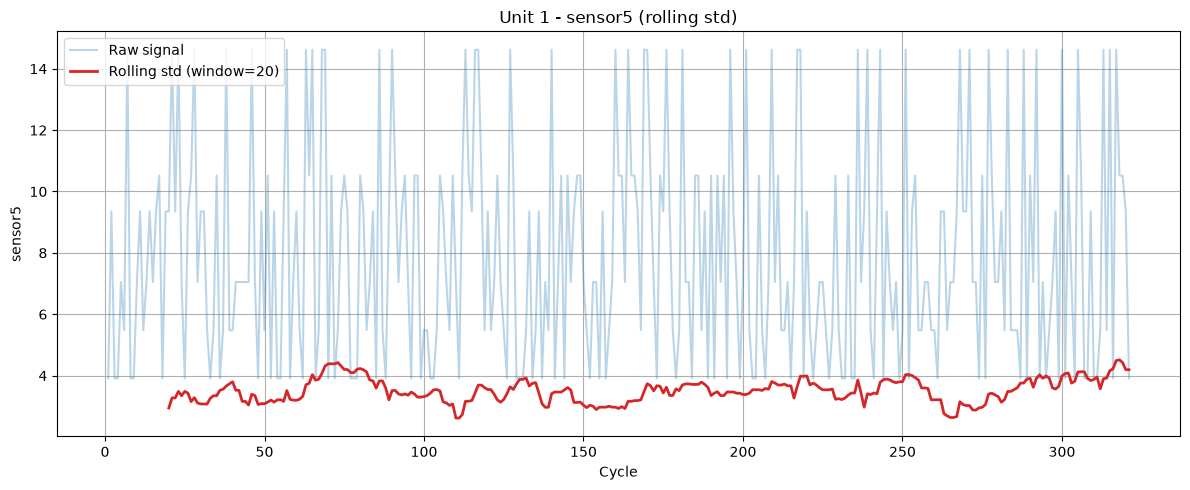

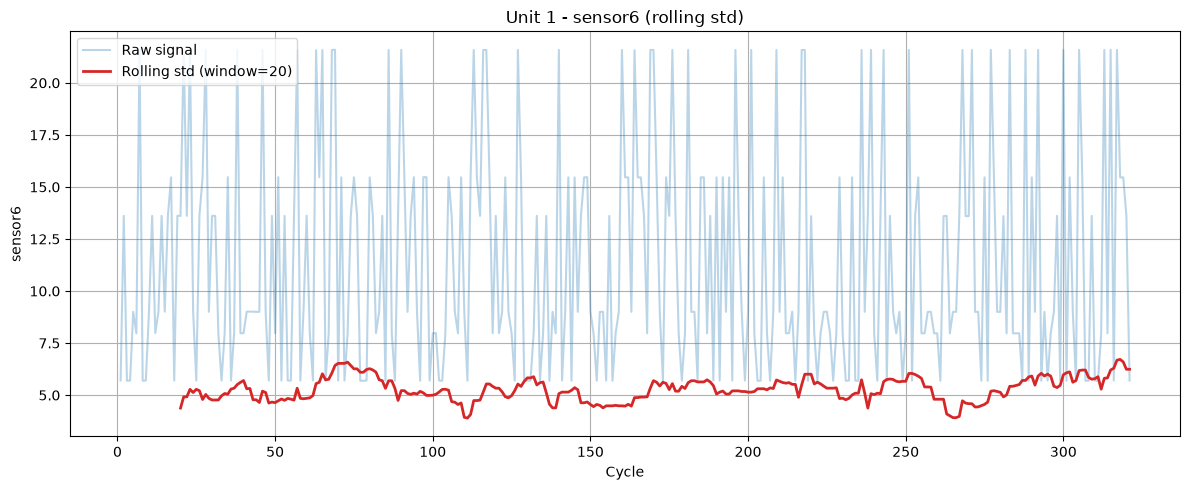

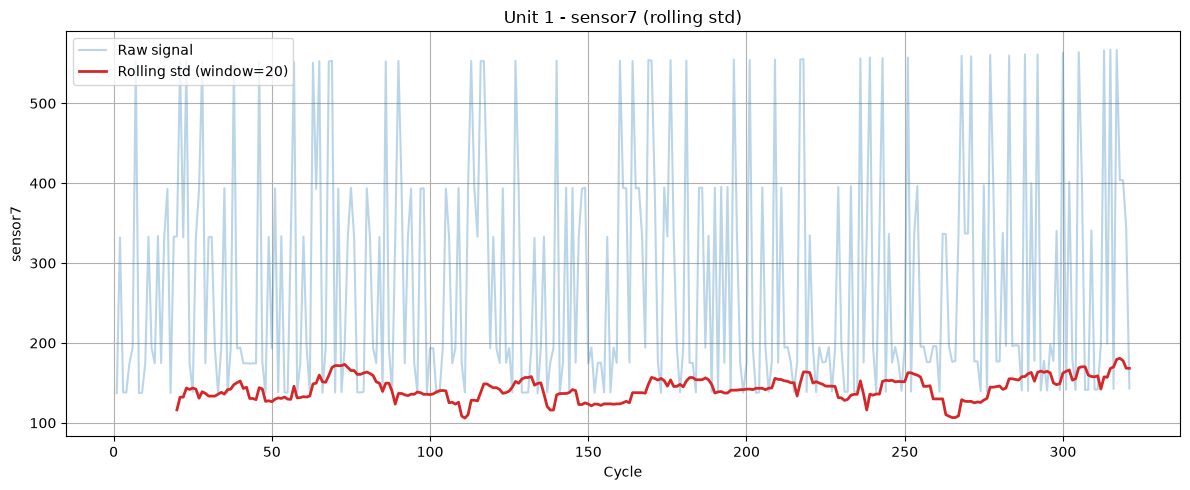

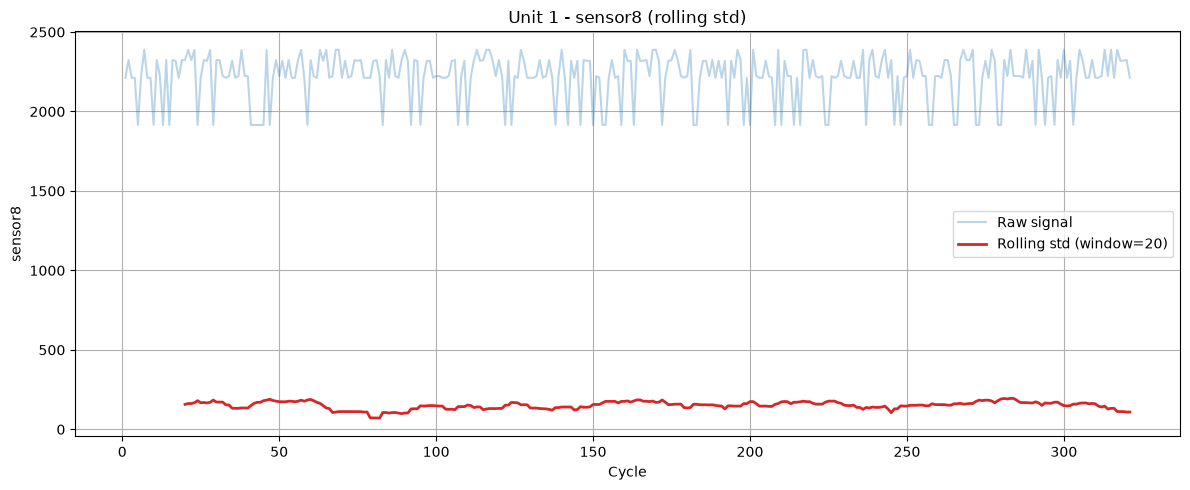

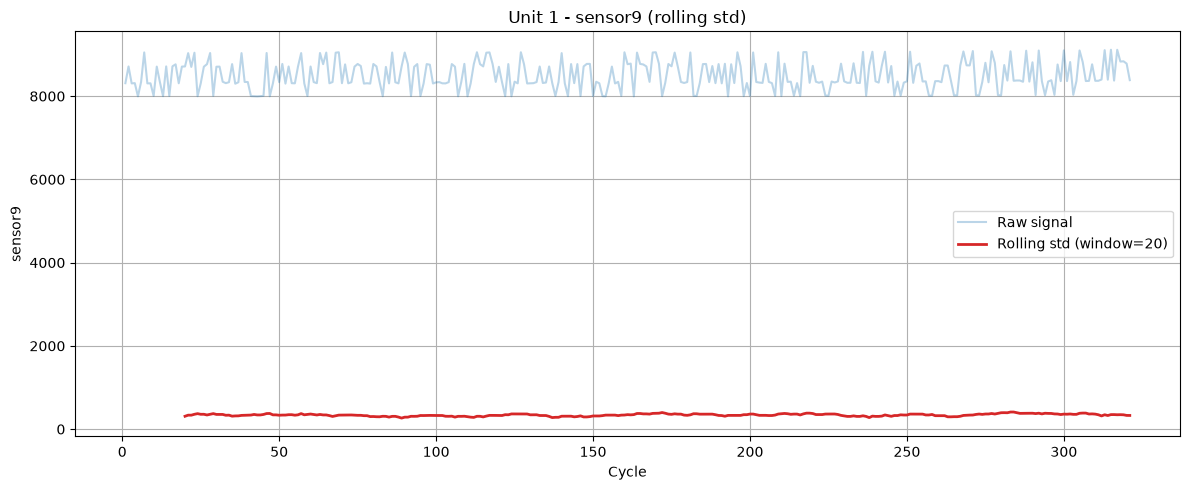

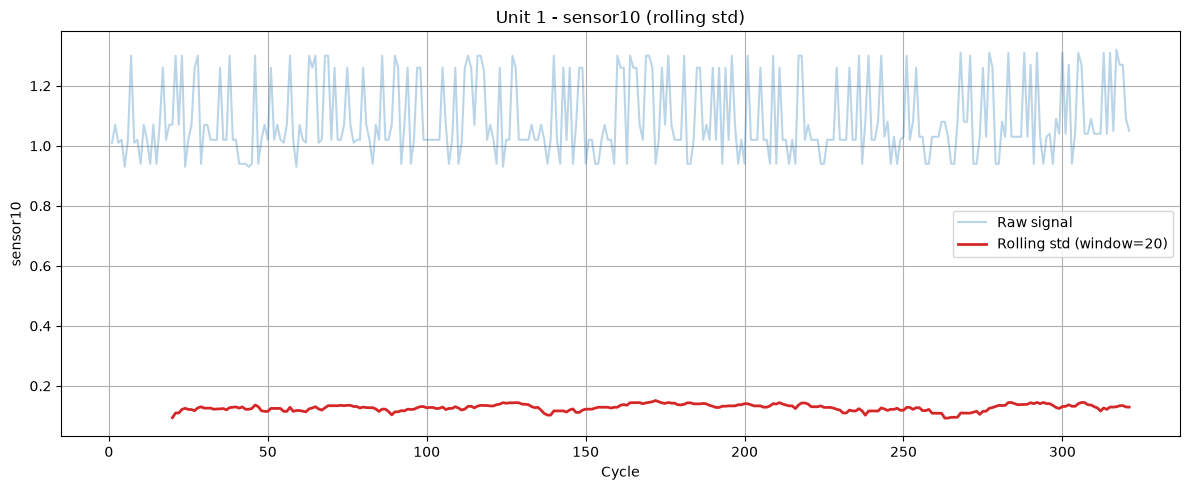

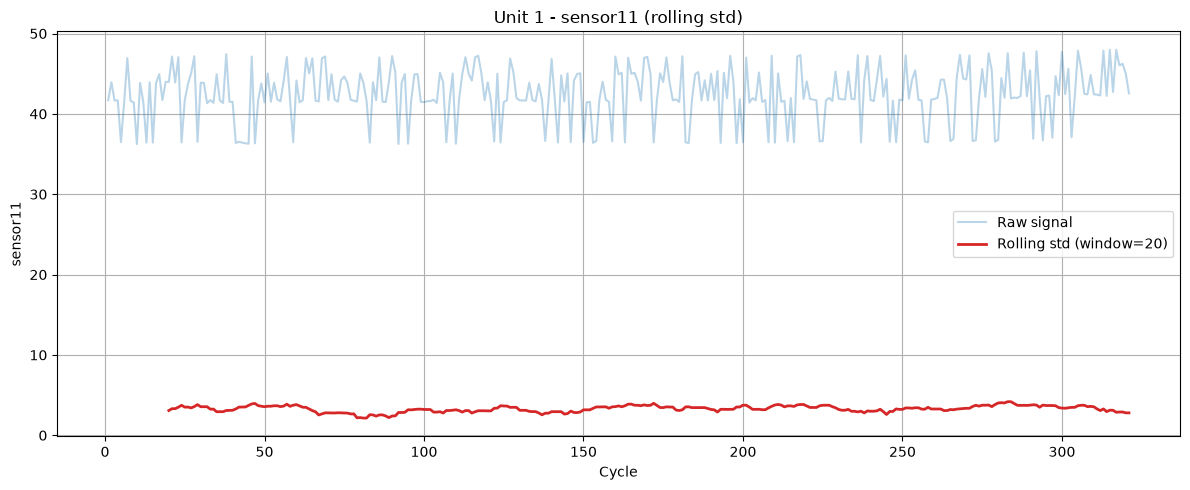

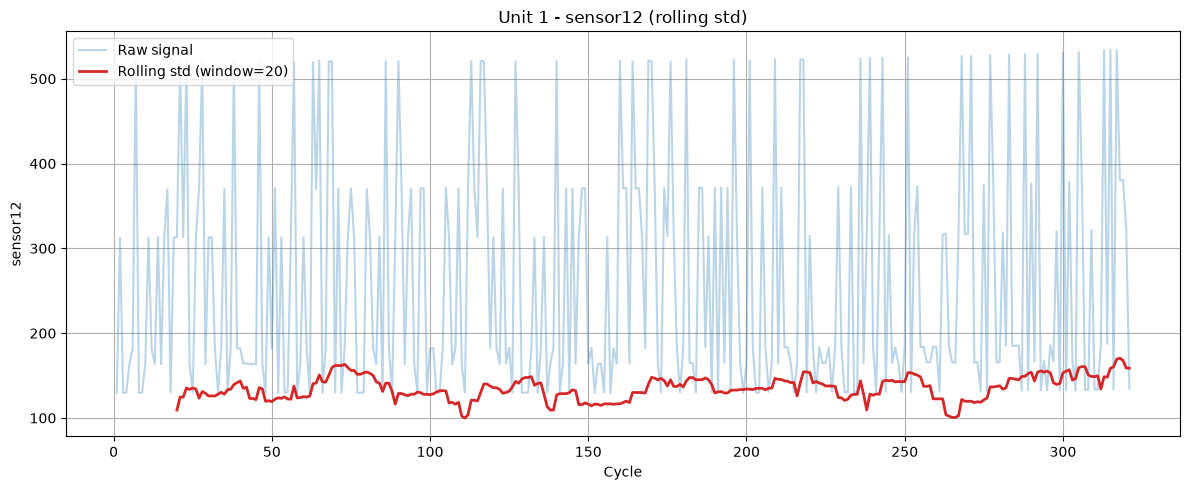

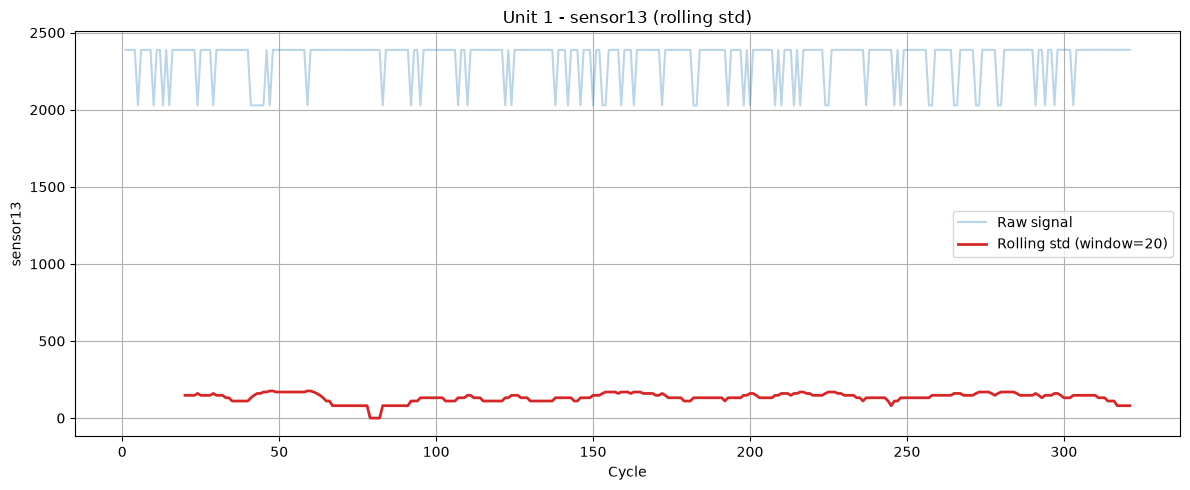

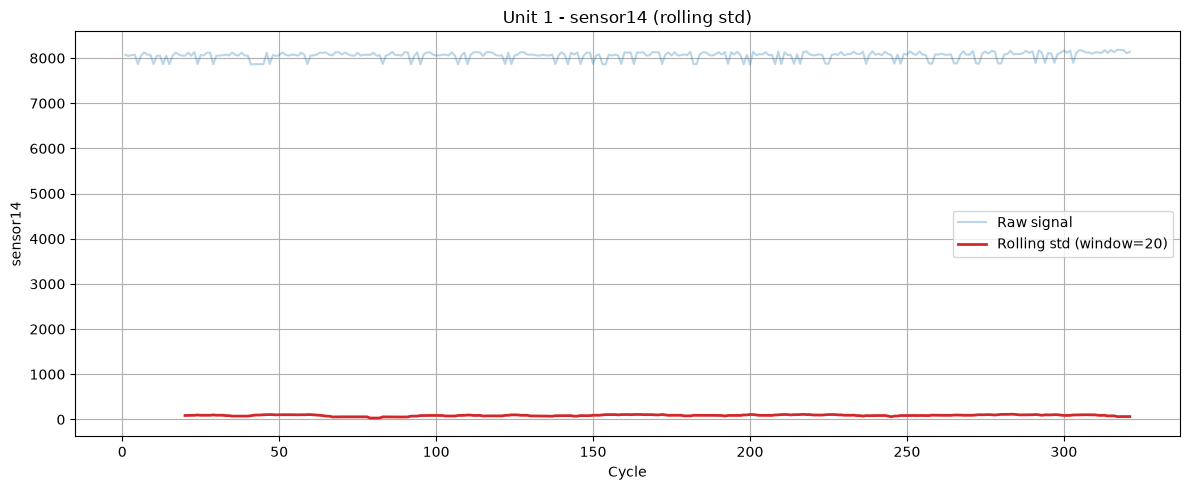

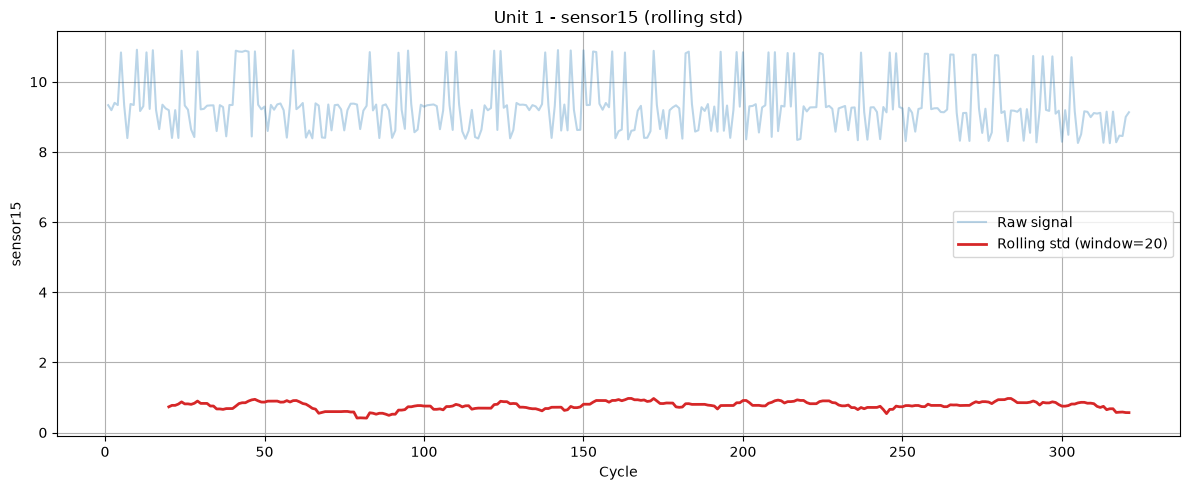

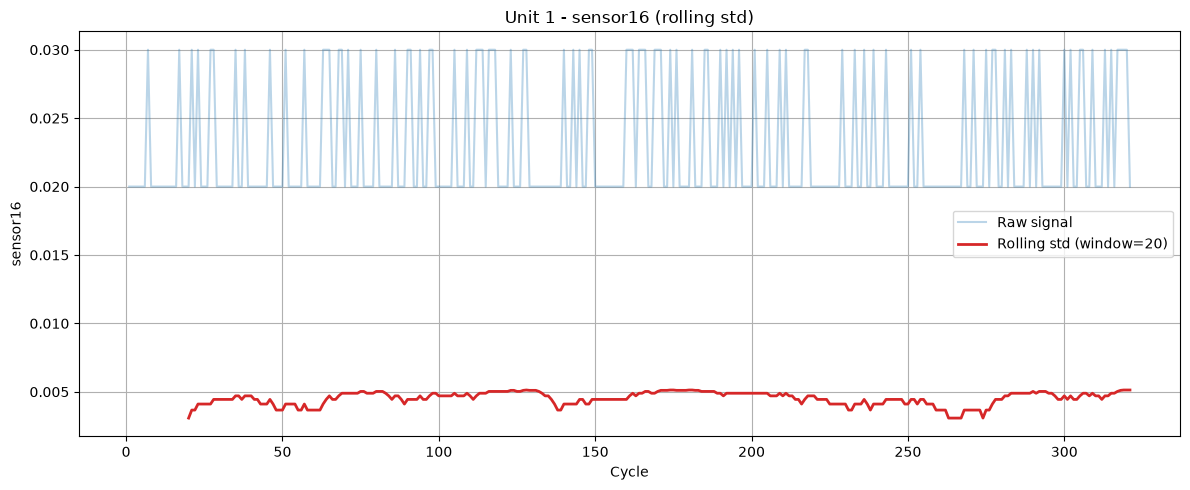

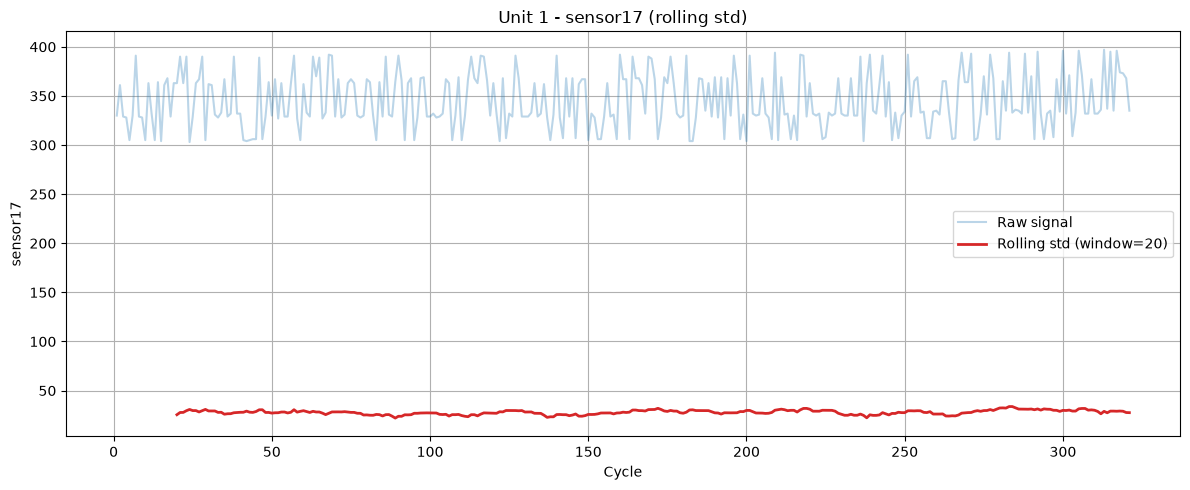

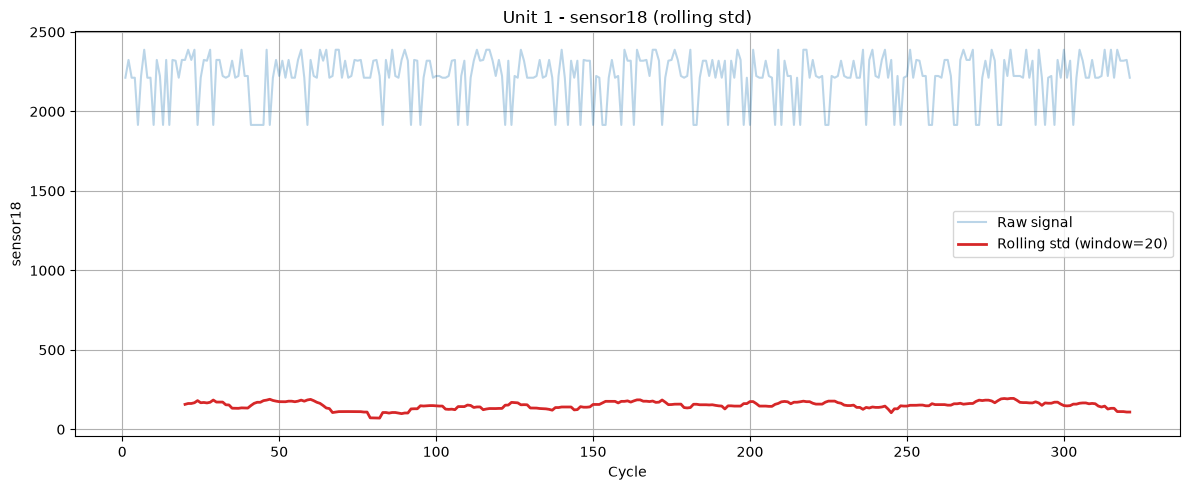

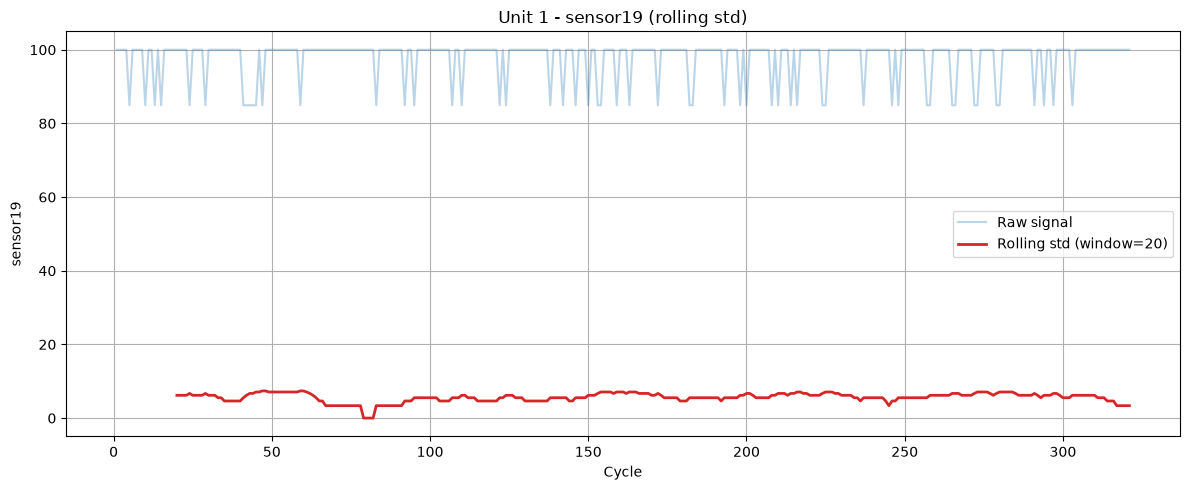

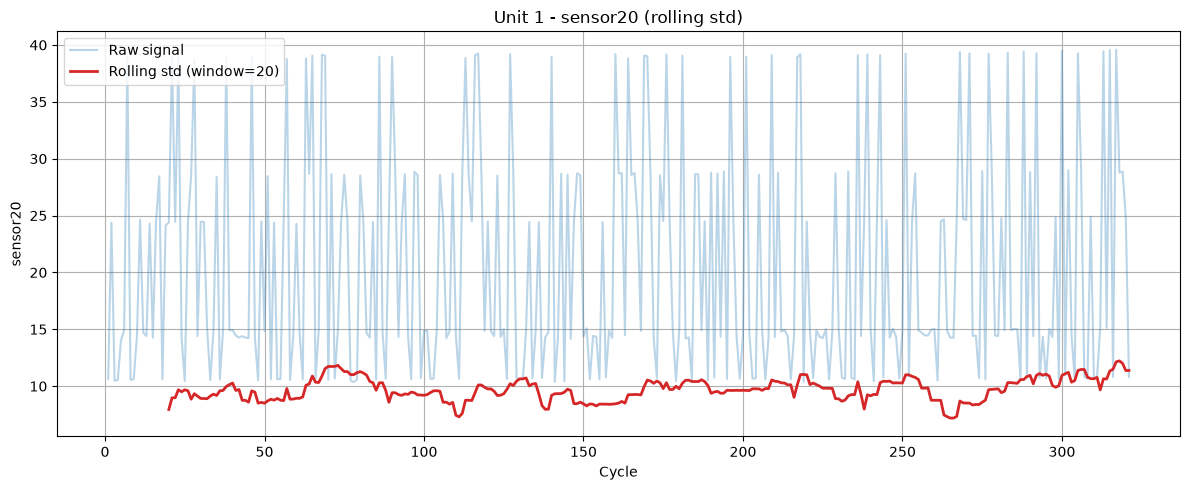

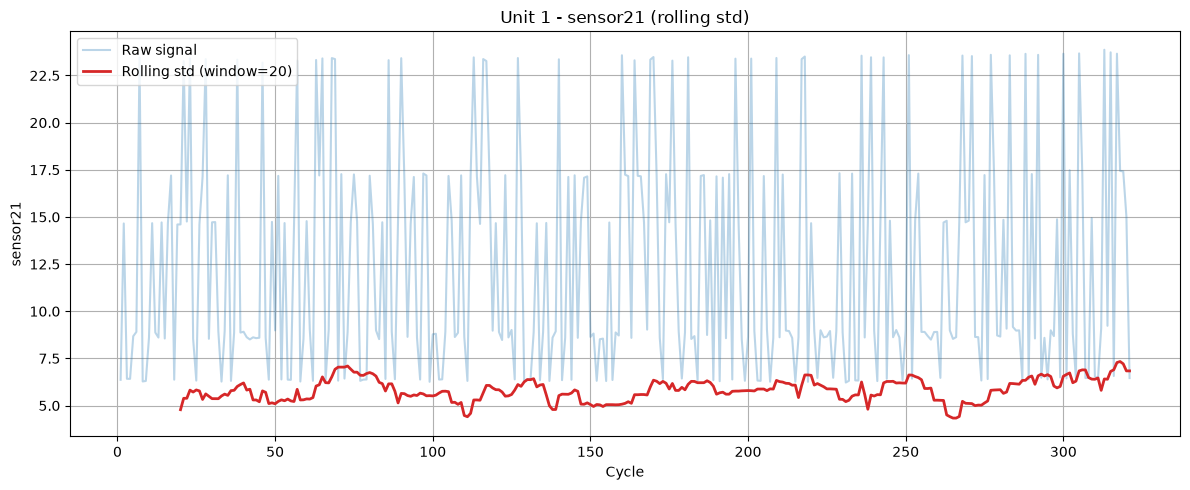

In [44]:
for i in range(1, 22):
    rolling_std(dataset, 1, f"sensor{i}")

As with the rolling mean, the rolling standard deviation is noisy for a single engine and is not always informative on its own; it will be considered together with other features in the next modeling phases.

## 6. Histograms

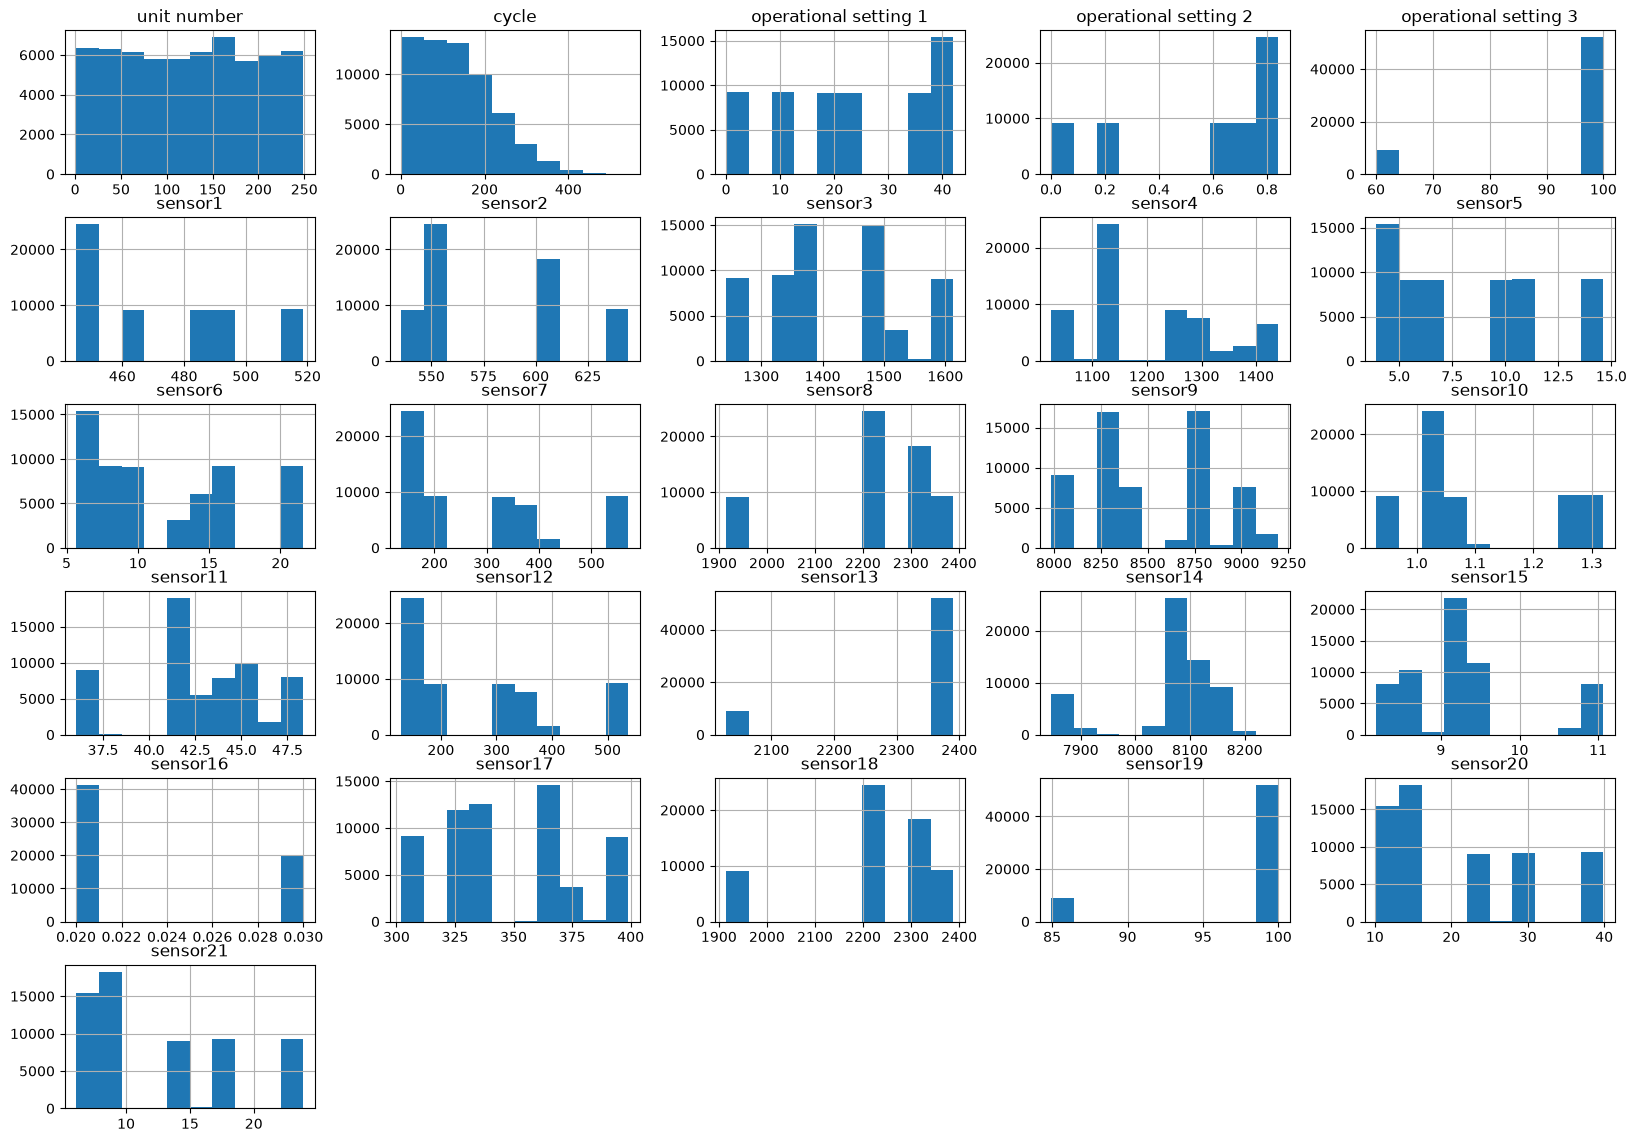

In [45]:
dataset.hist(figsize=(20, 14))
plt.show()

The analysis of the distributions did not reveal significant anomalies in the data. However, the different dispersion observed across sensors confirms that the features have different scales and variability, which will need to be taken into account in the next preprocessing and modeling phase.

## 7. Correlation Between Features (including Clustering)

In [46]:
corr = dataset.corr()

# set the diagonal to NaN
corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

corr_pairs = (
    corr.unstack()
    .dropna()
    .sort_values(key=abs, ascending=False)
)

print(corr_pairs)

sensor19               operational setting 3    1.000000
sensor18               sensor8                  0.999999
sensor13               operational setting 3    0.999998
sensor19               sensor13                 0.999998
sensor12               sensor7                  0.999993
sensor21               sensor20                 0.999897
sensor20               sensor7                  0.999142
sensor21               sensor7                  0.999140
sensor20               sensor12                 0.999082
sensor21               sensor12                 0.999080
sensor17               sensor3                  0.998693
                       sensor9                  0.998212
sensor9                sensor3                  0.998190
sensor6                sensor5                  0.996316
sensor21               sensor6                  0.996299
sensor20               sensor6                  0.996289
sensor7                sensor6                  0.993180
sensor12               sensor6 

The correlation matrix reveals many pairs of strongly correlated sensors. Since analyzing every single pair is not very interpretable or scalable, a hierarchical clustering of the sensors was applied in order to identify groups of sensors with similar behavior.

Figure saved to: figures/sensor_clustering.png


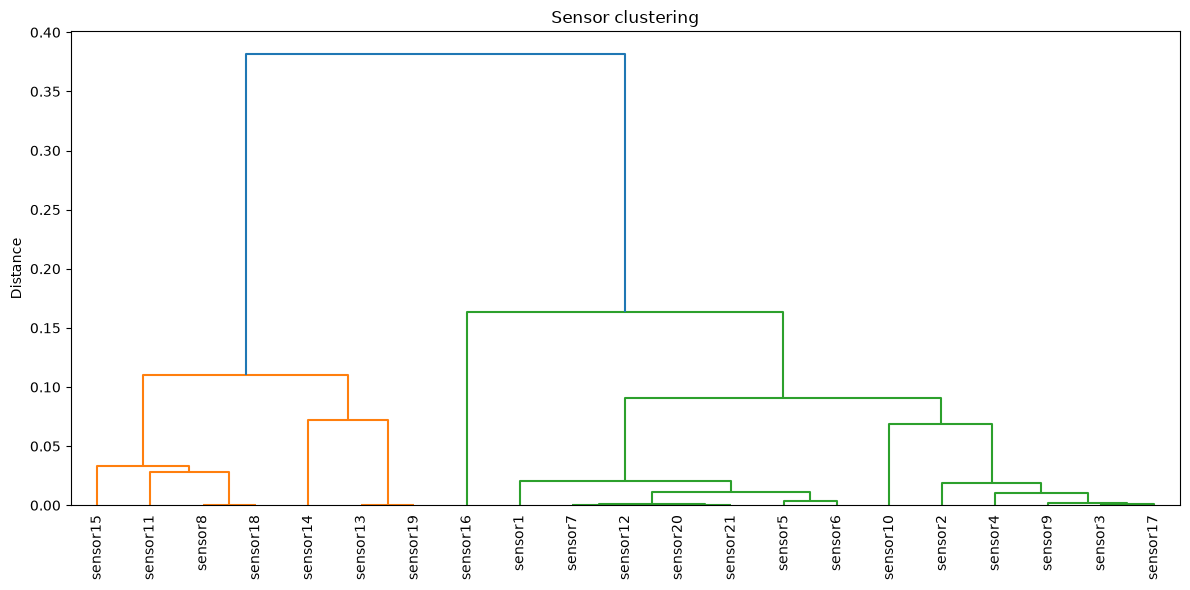

In [47]:
fig_dendrogram, Z = plot_sensor_dendrogram(dataset=dataset, save=True)

The distance between 2 sensors was defined as

$$
D(sensor_i, sensor_j) = 1 - \left|\rho\right|
$$

From the dendrogram it is possible to identify two main macro-clusters, each containing several sub-clusters characterized by small distances. This result confirms strong redundancy among several features of the dataset: some sensors show very similar behavior and may contain partially overlapping information.

This analysis will be useful in the next feature-selection phase, to evaluate whether the dataset's dimensionality can be reduced while keeping the information most relevant for RUL prediction.

## 8. RUL

We add the target column to the dataset.

In [48]:
max_cycle = dataset.groupby("unit number")["cycle"].transform("max")
dataset["RUL"] = max_cycle - dataset["cycle"]

dataset[["unit number", "cycle", "RUL"]].head()

,unit number,cycle,RUL
0,1,1,320
1,1,2,319
2,1,3,318
3,1,4,317
4,1,5,316


### 8.1 Correlation of the Features with the Target

In [49]:
corr_rul = dataset.corr()["RUL"].sort_values()
print(corr_rul)

cycle                   -0.610620
sensor14                -0.078126
sensor11                -0.056639
sensor16                -0.053804
sensor4                 -0.045881
sensor17                -0.032939
sensor3                 -0.032924
sensor9                 -0.024727
sensor10                -0.008924
sensor2                 -0.004443
sensor15                -0.003957
unit number             -0.003656
operational setting 1   -0.002380
operational setting 2   -0.002280
sensor12                -0.001639
sensor7                 -0.001429
sensor6                  0.001349
sensor13                 0.001501
sensor5                  0.001679
sensor1                  0.001889
sensor8                  0.002086
sensor19                 0.002303
operational setting 3    0.002303
sensor18                 0.002765
sensor21                 0.002791
sensor20                 0.002812
RUL                      1.000000
Name: RUL, dtype: float64


We note the strong correlation between cycle and RUL, which is expected since RUL is derived directly from that column. We also note that all the remaining features are almost completely uncorrelated with the target.

## 9. Analysis by Operating Condition

Since the sensors can be influenced both by engine degradation and by the operating conditions, the dataset is analyzed separately for each operating regime. This makes it possible to distinguish variations due to the system's operating point from those associated with the engine's progressive degradation.

First, the 6 operating conditions are identified.

In [50]:
op_columns = [
    "operational setting 1",
    "operational setting 2",
    "operational setting 3",
]

dataset[op_columns] = dataset[op_columns].round(0)

dataset["operating condition"] = (
    dataset.groupby(op_columns).ngroup()
)

display(
    dataset[op_columns + ["operating condition"]]
    .drop_duplicates()
    .sort_values("operating condition")
)

,operational setting 1,operational setting 2,operational setting 3,operating condition
6,0.0,0.0,100.0,0
16,10.0,0.0,100.0,1
1,20.0,1.0,100.0,2
4,25.0,1.0,60.0,3
5,35.0,1.0,100.0,4
0,42.0,1.0,100.0,5


We now look at the distribution of the operating conditions.

Figure saved to: figures/operating_conditions_distribution.png


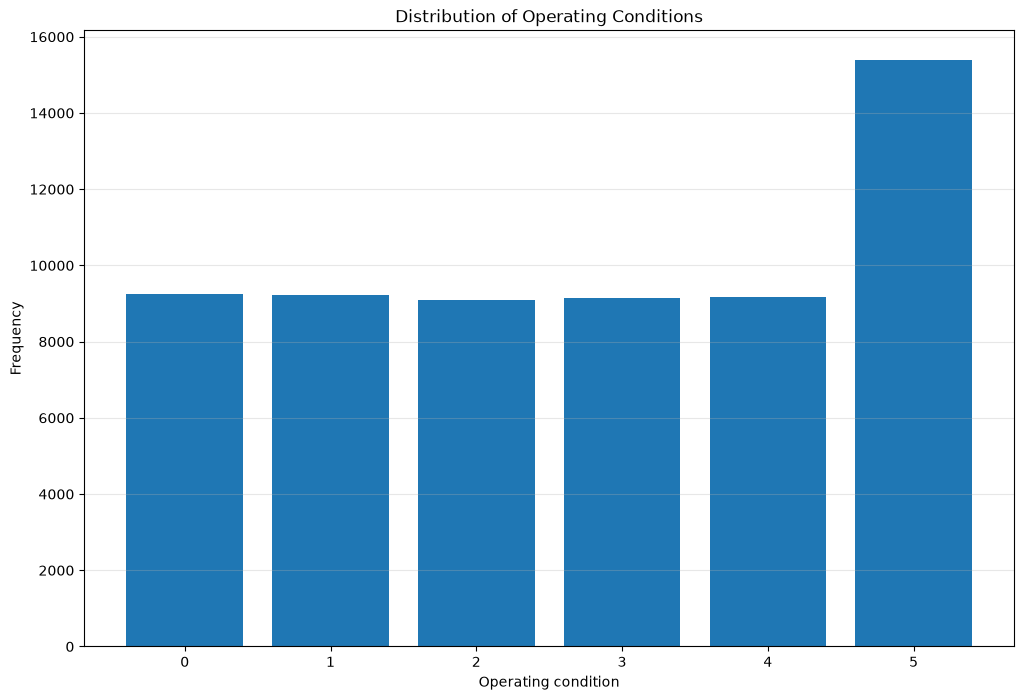

In [51]:
counts = (
    dataset["operating condition"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 8))

plt.bar(counts.index, counts.values)

plt.xlabel("Operating condition")
plt.ylabel("Frequency")
plt.title("Distribution of Operating Conditions")

plt.grid(axis="y", alpha=0.3)

save_figure(plt.gcf(), "operating_conditions_distribution")

plt.show()

We note that the operating condition identified by id 5 is the most frequent, while the remaining 4 have roughly the same frequency.

We now compute the mean and standard deviation of each sensor by operating condition.

### 9.1 Mean

In [52]:
sensor_columns = [f"sensor{i}" for i in range(1, 22)]

sensor_means = (
    dataset.groupby("operating condition")[sensor_columns].mean()
)

print("\nSensor means by operating condition:\n")
print(sensor_means)


Sensor means by operating condition:

                     sensor1     sensor2      sensor3      sensor4  sensor5  \
operating condition                                                           
0                     518.67  642.496738  1588.519059  1405.249438    14.62   
1                     489.05  604.700575  1500.003491  1307.423831    10.52   
2                     491.19  607.326724  1483.501860  1249.568890     9.35   
3                     462.54  536.738590  1260.672766  1046.772438     7.05   
4                     449.44  555.564542  1364.709756  1128.238337     5.48   
5                     445.00  549.477912  1352.562715  1124.490963     3.91   

                       sensor6     sensor7      sensor8      sensor9  \
operating condition                                                    
0                    21.599282  555.114113  2388.084244  9063.492293   
1                    15.482330  395.403328  2318.940497  8785.888140   
2                    13.639413  335.2137

### 9.2 Standard Deviation

In [53]:
sensor_stds = (
    dataset.groupby("operating condition")[sensor_columns].std()
)

print("\nSensor standard deviations by operating condition:\n")
print(sensor_stds)


Sensor standard deviations by operating condition:

                     sensor1   sensor2   sensor3   sensor4  sensor5   sensor6  \
operating condition                                                             
0                        0.0  0.514416  6.707031  9.731900      0.0  0.014899   
1                        0.0  0.517158  6.537669  9.392014      0.0  0.014746   
2                        0.0  0.508334  6.635482  8.893205      0.0  0.023126   
3                        0.0  0.385915  5.818127  7.476698      0.0  0.012161   
4                        0.0  0.485350  6.446601  8.651547      0.0  0.013209   
5                        0.0  0.464344  6.596366  9.019432      0.0  0.010704   

                      sensor7   sensor8    sensor9  sensor10  sensor11  \
operating condition                                                      
0                    3.468158  0.148508  19.271059  0.003505  0.295673   
1                    2.380231  0.181144  18.893910  0.003137  0.292329   
2 

Some sensors show different mean values across operating conditions, but remain practically constant within each operating condition (standard deviation close to zero). This suggests that these features mainly describe the system's operating point rather than the engine's degradation process.

We now show heatmaps of the sensor mean and standard deviation by operating condition.

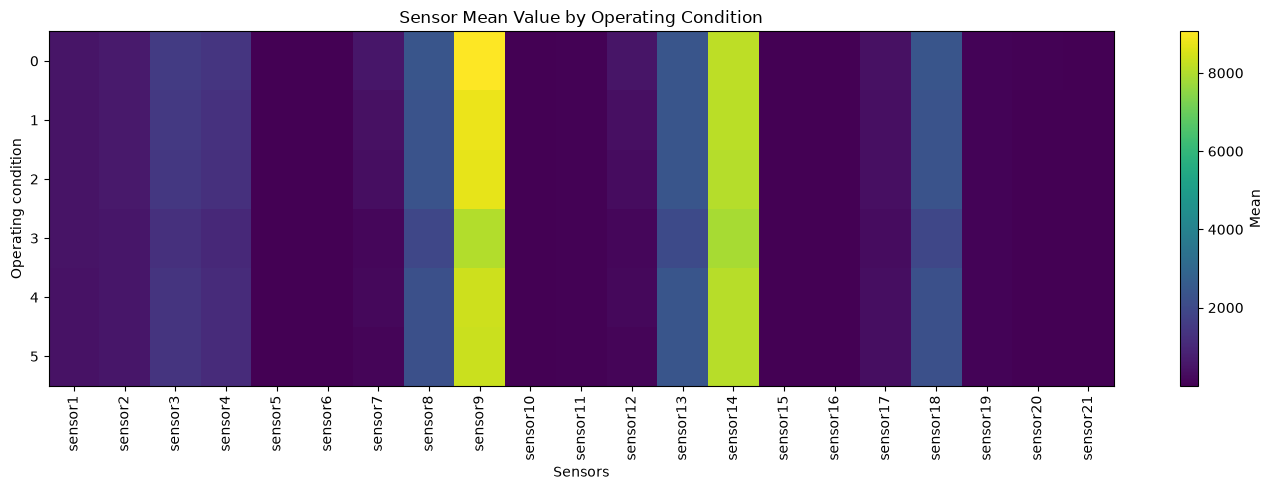

In [54]:
plt.figure(figsize=(14, 5))

plt.imshow(sensor_means.values, aspect="auto")

plt.colorbar(label="Mean")

plt.xticks(np.arange(len(sensor_columns)), sensor_columns, rotation=90)
plt.yticks(np.arange(len(sensor_means.index)), sensor_means.index)

plt.xlabel("Sensors")
plt.ylabel("Operating condition")

plt.title("Sensor Mean Value by Operating Condition")

plt.tight_layout()

plt.show()

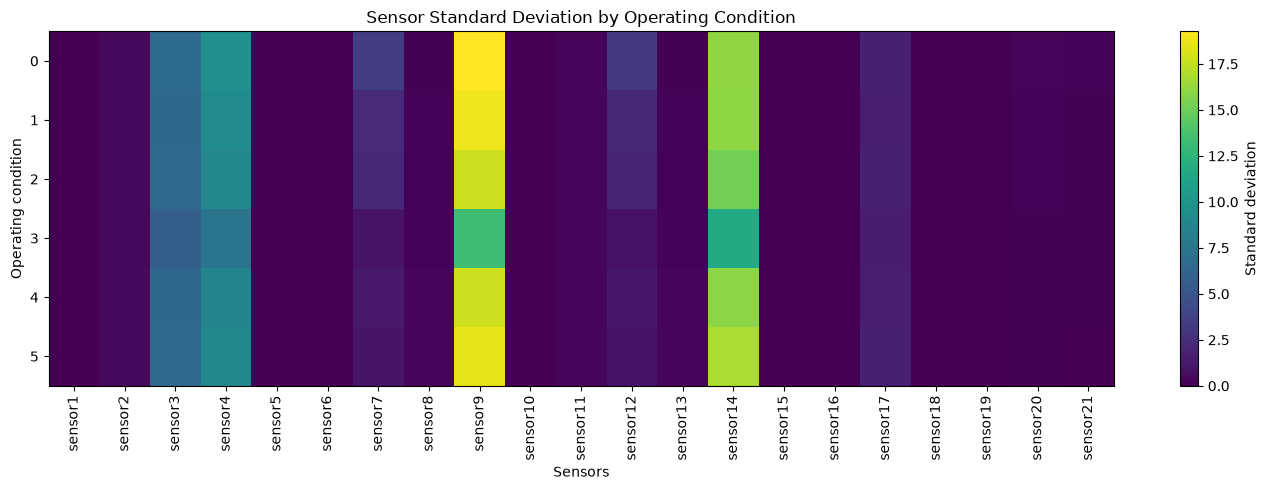

In [55]:
plt.figure(figsize=(14, 5))

plt.imshow(sensor_stds.values, aspect="auto")

plt.colorbar(label="Standard deviation")

plt.xticks(np.arange(len(sensor_columns)), sensor_columns, rotation=90)
plt.yticks(np.arange(len(sensor_stds.index)), sensor_stds.index)

plt.xlabel("Sensors")
plt.ylabel("Operating condition")

plt.title("Sensor Standard Deviation by Operating Condition")

plt.tight_layout()

plt.show()

### 9.3 Trend

Finally, we look at how a few sensors evolve as a function of RUL, separately for each operating condition. We focus on the sensors most correlated (in absolute value) with the target, identified in section 8.1.

['sensor14', 'sensor11', 'sensor16', 'sensor4', 'sensor17', 'sensor3', 'sensor9', 'sensor10', 'sensor2', 'sensor15', 'sensor20', 'sensor21', 'sensor18', 'sensor19', 'sensor8', 'sensor1', 'sensor5', 'sensor12', 'sensor13', 'sensor7', 'sensor6']


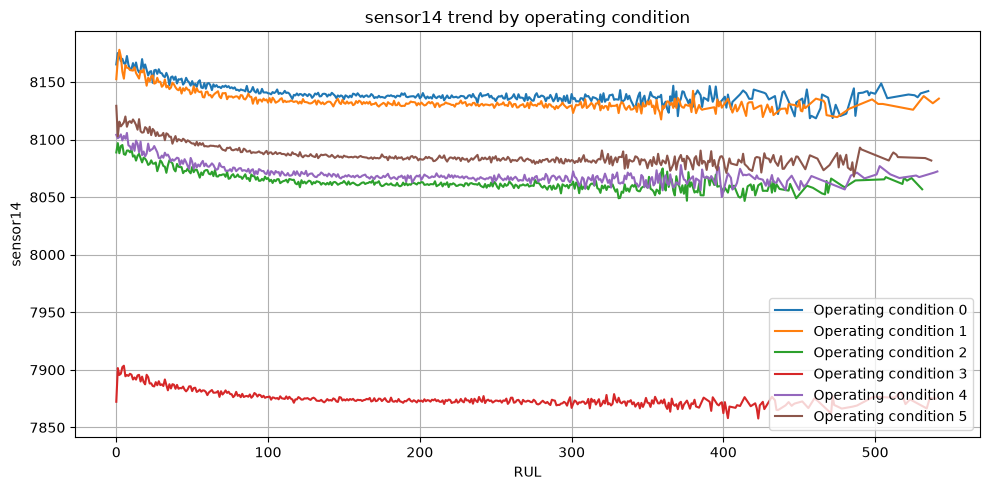

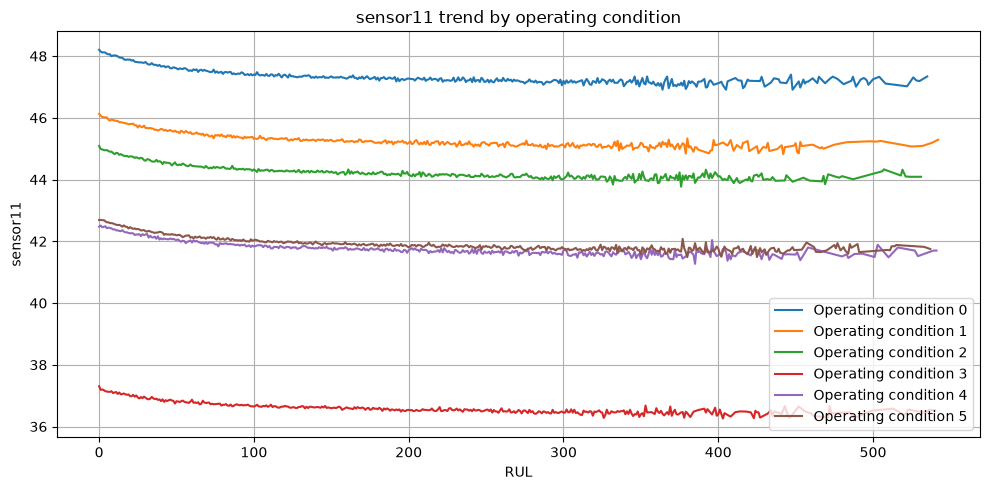

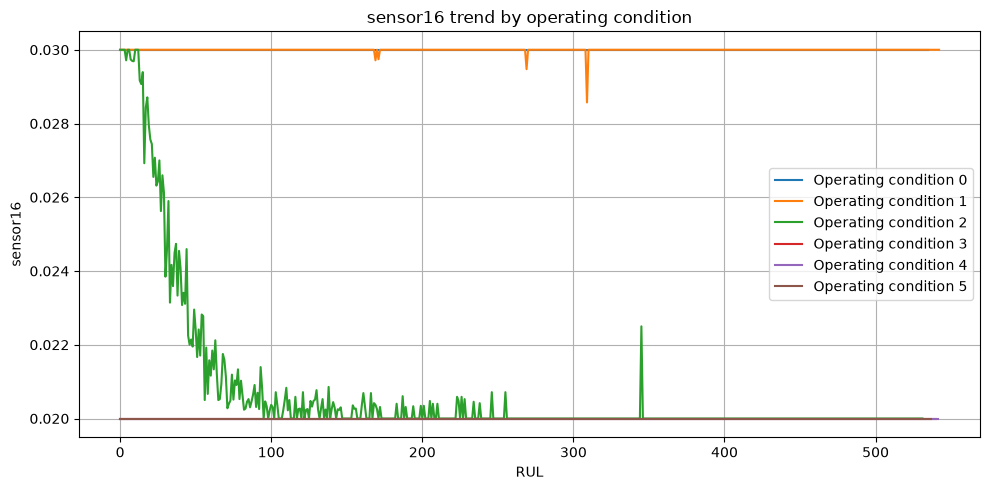

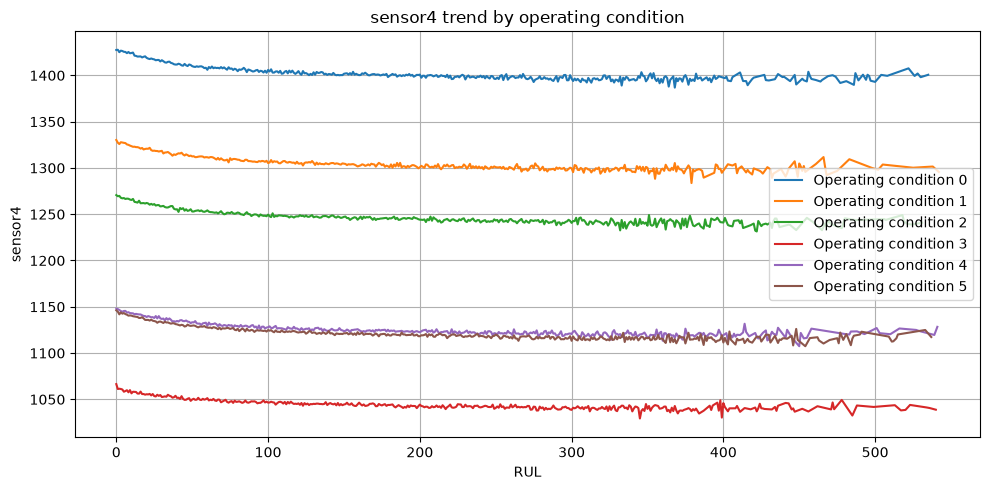

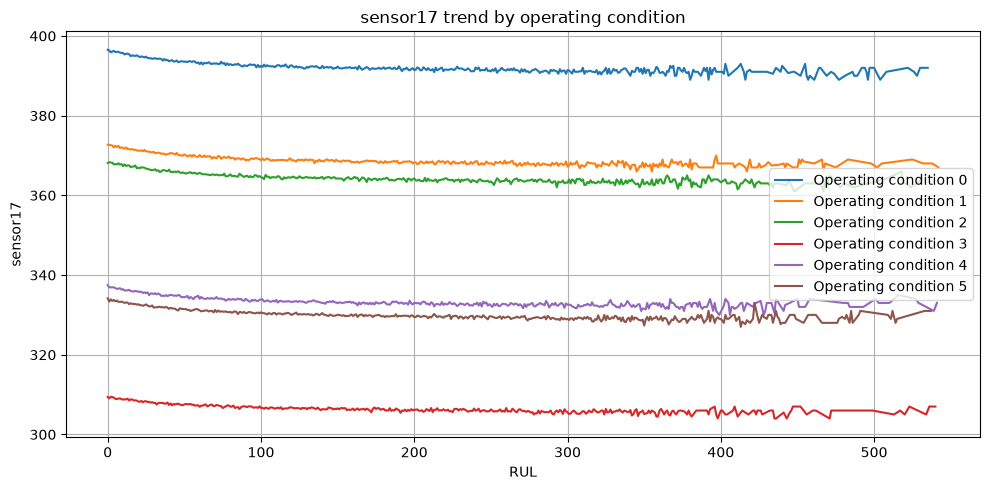

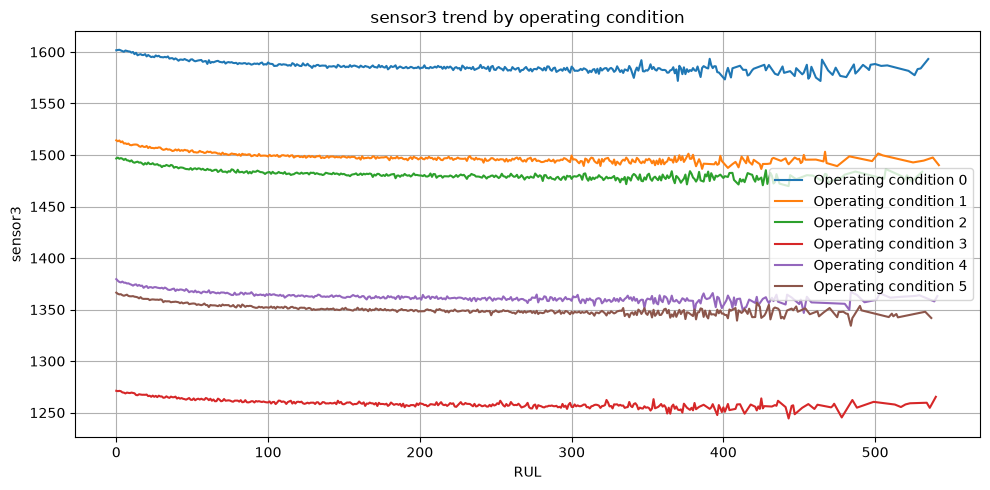

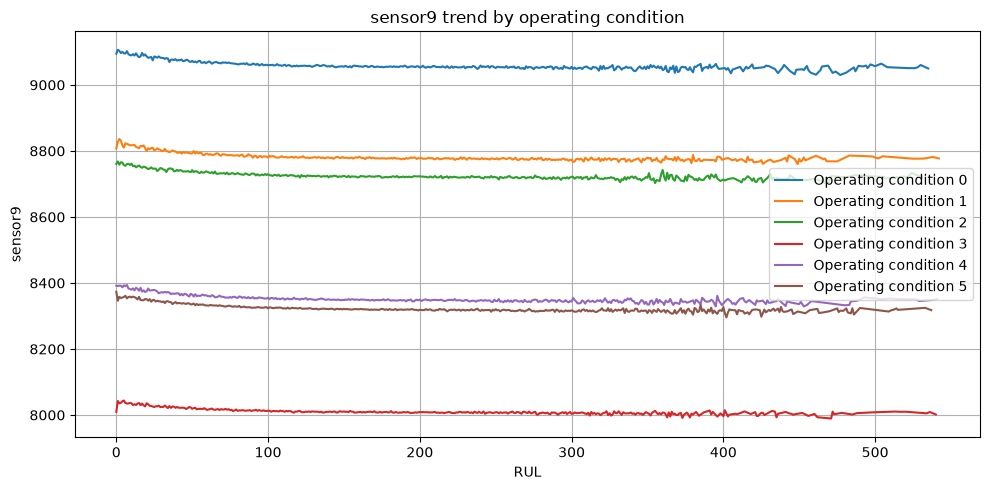

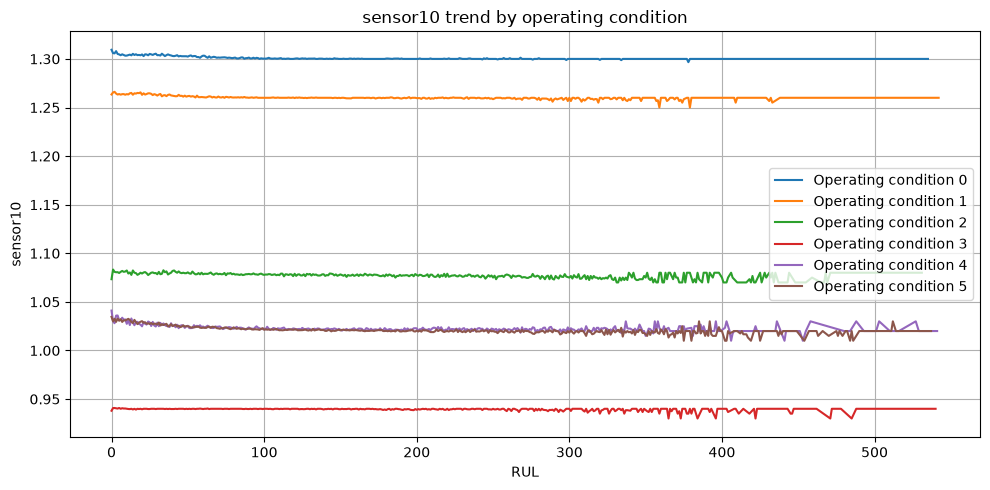

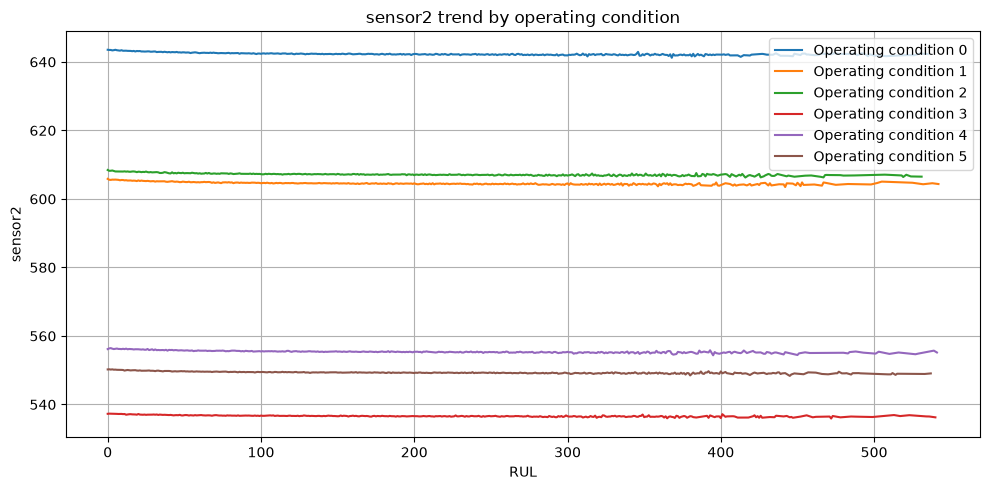

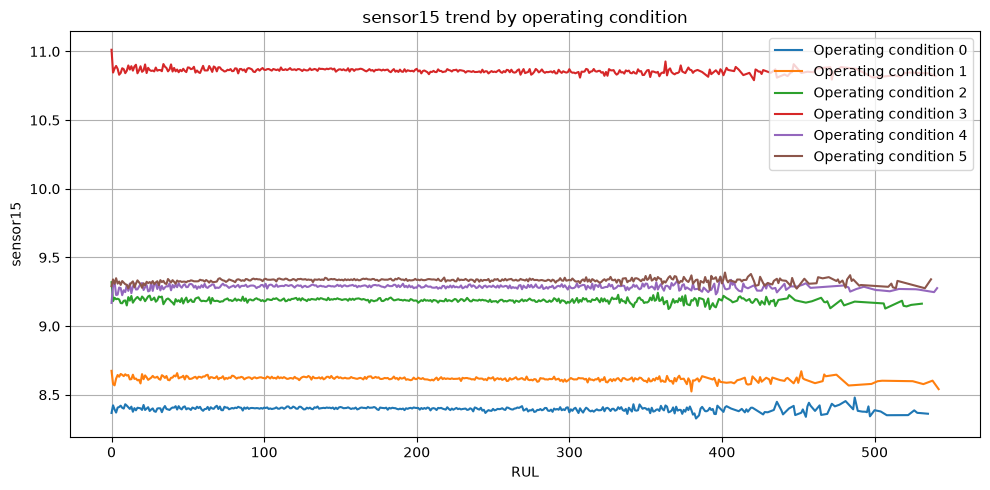

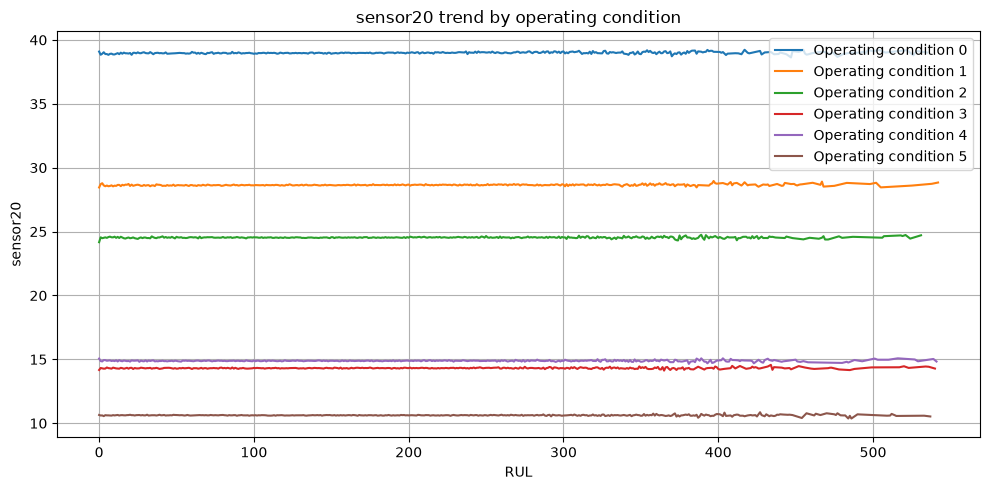

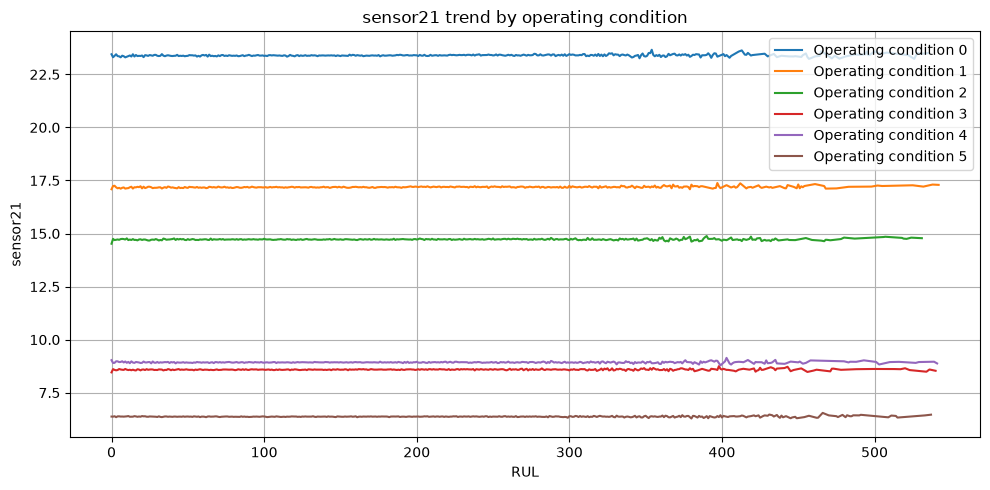

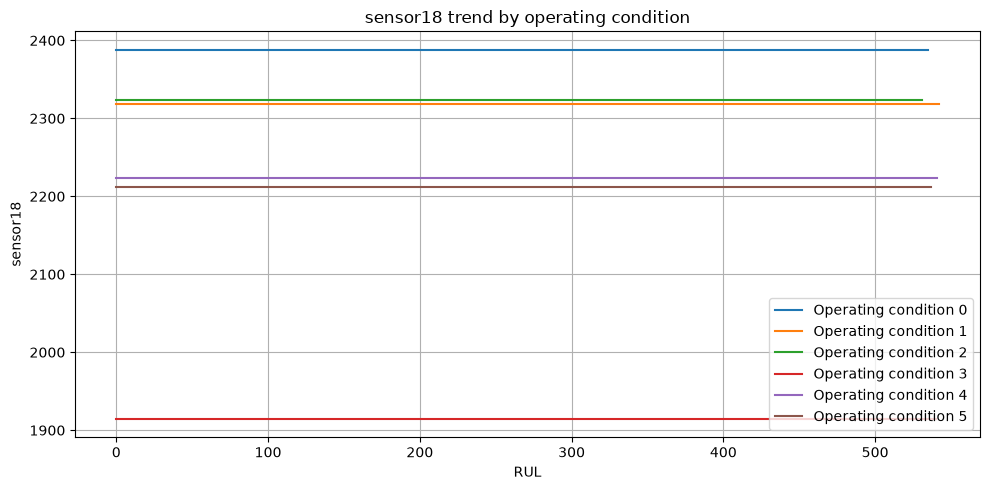

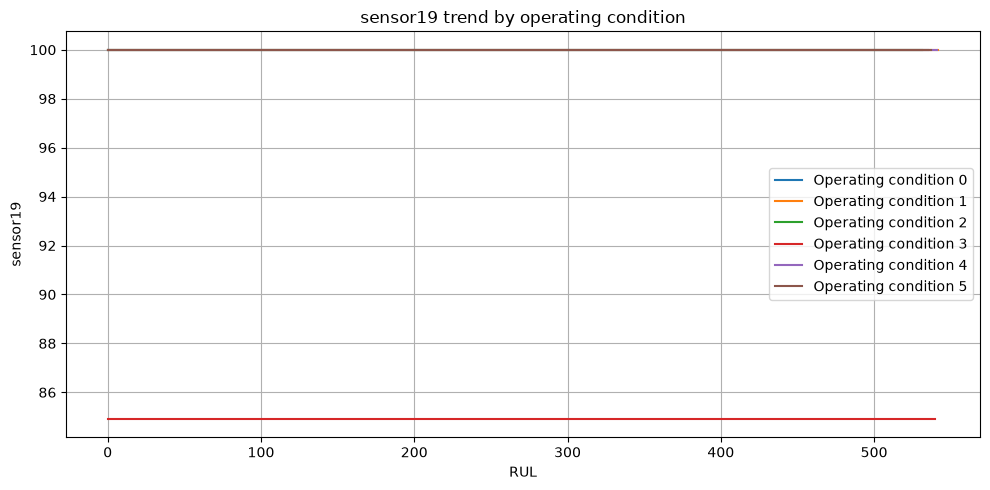

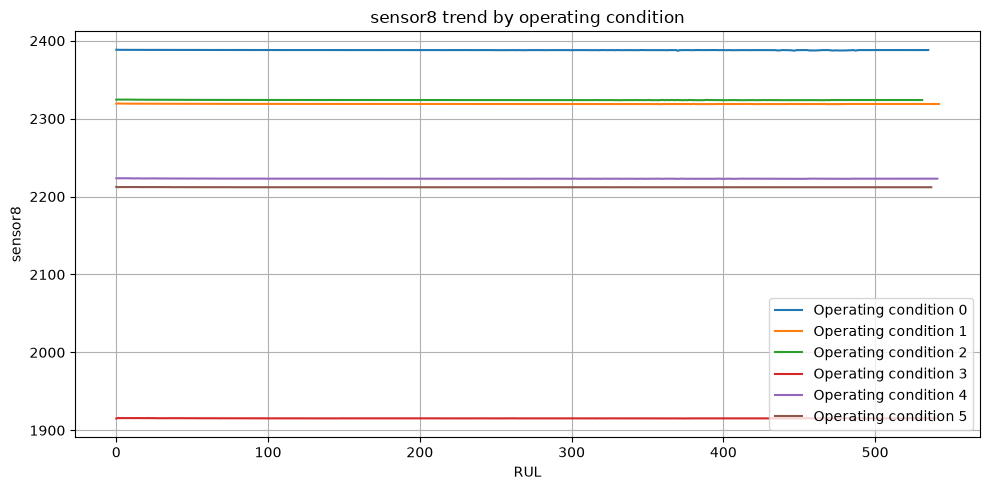

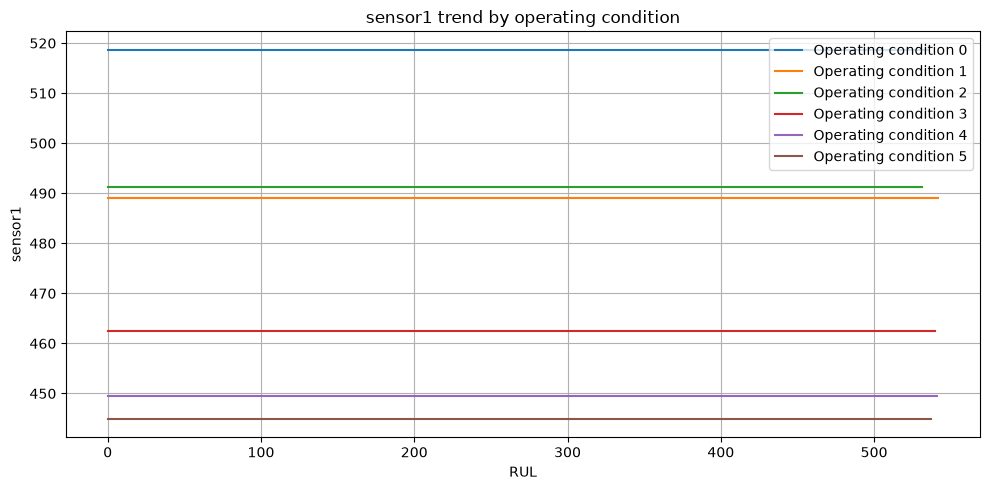

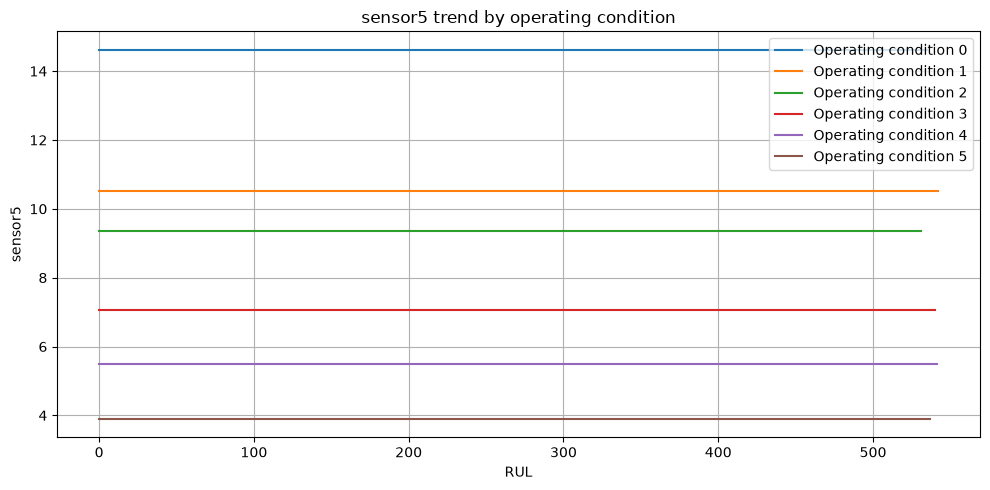

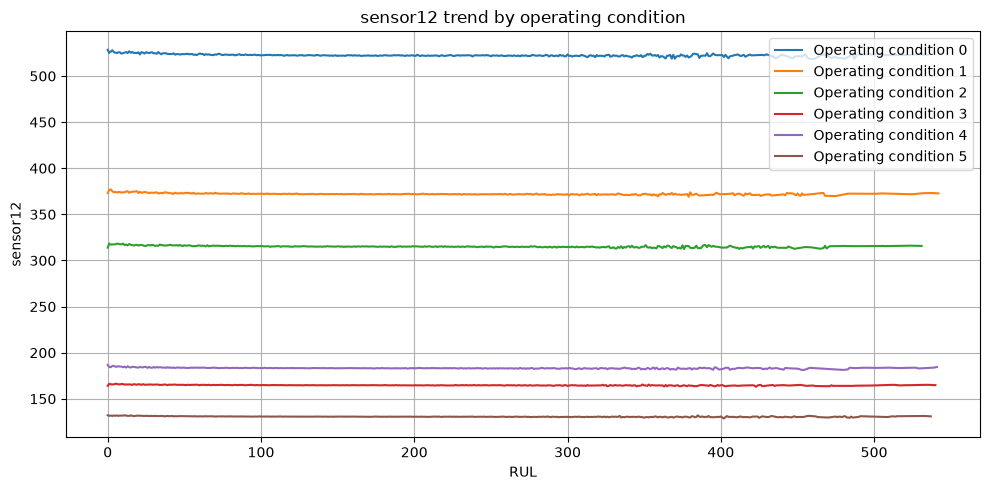

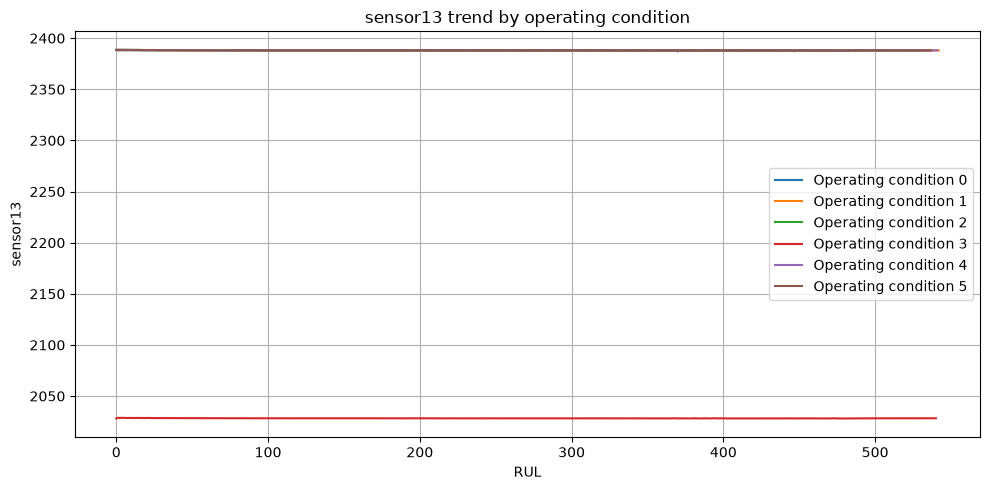

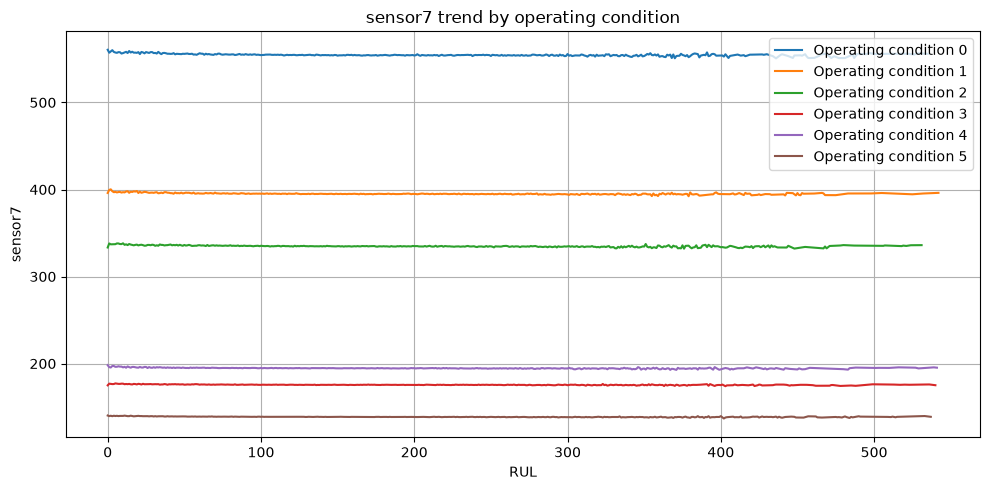

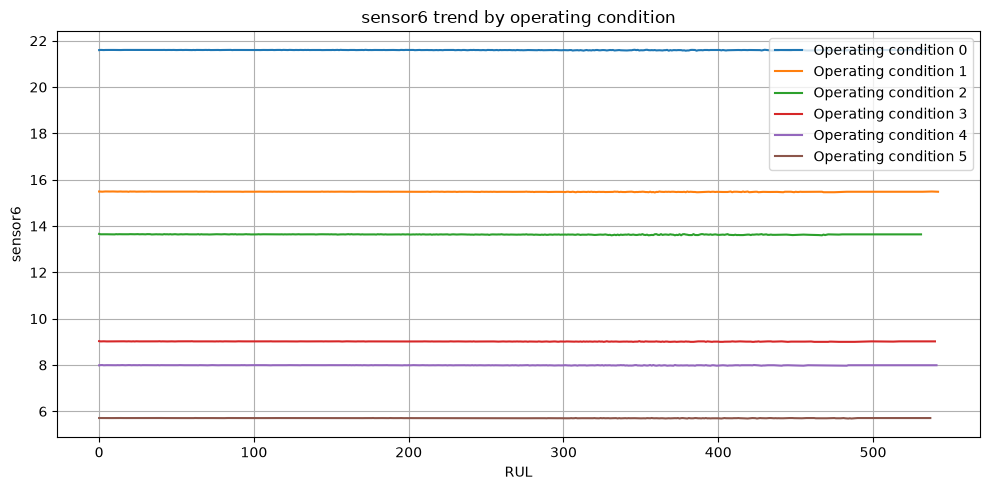

In [56]:
selected_sensors = (
    corr_rul.drop(
        index=[
            "RUL",
            "cycle",
            "unit number",
            "operational setting 1",
            "operational setting 2",
            "operational setting 3",
        ],
        errors="ignore",
    )
    .abs()
    .sort_values(ascending=False)
    .head(21)
    .index
    .tolist()
)

print(selected_sensors)

for sensor in selected_sensors:
    plot_sensor_by_operating_condition(
        dataset,
        sensor=sensor,
        x="RUL",
        condition_col="operating condition",
    )

Some sensors show almost constant values that depend on the operating condition, indicating a stronger relationship with the operating point than with engine degradation. Other sensors instead show a decreasing trend as RUL increases, making them potentially more informative for estimating the remaining useful life.

### 9.4 Correlation with the Target

In [57]:
conditions = sorted(dataset["operating condition"].unique())

correlation_by_condition = []

for condition in conditions:
    subset = dataset[dataset["operating condition"] == condition]

    # Constant sensors within a condition have std = 0, so their correlation
    # with the RUL is undefined (NaN): the warning is expected and silenced
    with np.errstate(invalid="ignore"):
        correlations = [
            subset[sensor].corr(subset["RUL"]) for sensor in sensor_columns
        ]

    correlation_by_condition.append(correlations)

# build the resulting DataFrame
corr_condition_df = pd.DataFrame(
    correlation_by_condition,
    index=[f"Condition {c}" for c in conditions],
    columns=sensor_columns,
)

corr_condition_df

,sensor1,sensor2,sensor3,sensor4,sensor5,sensor6,sensor7,sensor8,sensor9,sensor10,sensor11,sensor12,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21
Condition 0,NaN,-0.585342,-0.603595,-0.657667,1.024963e-16,-0.135955,-0.254715,-0.590894,-0.510558,-0.361705,-0.689286,-0.272689,-0.591872,-0.429323,-0.040991,1.024963e-16,-0.625899,NaN,NaN,0.080299,0.068547
Condition 1,1.389639e-16,-0.594763,-0.600974,-0.678704,-1.389639e-16,-0.248634,-0.272343,-0.680927,-0.525739,-0.378926,-0.702216,-0.293122,-0.680948,-0.441722,-0.072661,-2.170530e-02,-0.624980,NaN,NaN,0.072347,0.080337
Condition 2,5.844537e-16,-0.548239,-0.591386,-0.660975,NaN,-0.201423,-0.305132,-0.638591,-0.520083,-0.246807,-0.690117,-0.321076,-0.638242,-0.440934,-0.032767,-4.941730e-01,-0.615825,NaN,NaN,0.027680,0.031808
Condition 3,-1.579832e-16,-0.451263,-0.527026,-0.589808,1.579832e-16,-0.204642,-0.279255,-0.400077,-0.522362,-0.167790,-0.650222,-0.305005,-0.400384,-0.463922,-0.076461,1.579832e-16,-0.546463,NaN,NaN,0.041293,0.049659
Condition 4,NaN,-0.527073,-0.573343,-0.652493,5.232521e-17,-0.141221,-0.300263,-0.461952,-0.525441,-0.280067,-0.690476,-0.311789,-0.461694,-0.451063,0.013059,NaN,-0.596206,NaN,NaN,0.016715,-0.002484
Condition 5,NaN,-0.500543,-0.599331,-0.668716,-1.165082e-16,-0.184983,-0.316318,-0.280058,-0.532590,-0.401337,-0.698638,-0.341806,-0.282397,-0.465662,0.079753,1.165082e-16,-0.619563,NaN,NaN,-0.003005,0.002030


In [58]:
nan_corr = corr_condition_df.isna()

nan_corr.sum()

sensor1     3
sensor2     0
sensor3     0
sensor4     0
sensor5     1
sensor6     0
sensor7     0
sensor8     0
sensor9     0
sensor10    0
sensor11    0
sensor12    0
sensor13    0
sensor14    0
sensor15    0
sensor16    1
sensor17    0
sensor18    6
sensor19    6
sensor20    0
sensor21    0
dtype: int64

We note that some sensors have a NaN correlation with the target: this happens because those sensors have constant values within the different operating conditions, and therefore an almost completely null variance.

## 10. Conclusions

The exploratory analysis made it possible to identify several relevant characteristics of the C-MAPSS dataset. Some features were found to have very limited variability or to be mainly tied to the operating conditions, thus providing redundant information with respect to the engine's degradation process.

The analysis stratified by operating condition showed that some sensors maintain a coherent trend with respect to RUL regardless of the operating condition, suggesting a possible link with the component's degradation. In contrast, other sensors show variations that are mainly due to changes in the operating regime, with trends that are not very significant with respect to the remaining useful life.

The correlation and sensor-clustering analysis also highlighted the presence of groups of strongly correlated features, indicating possible informational redundancy. These results will be used in the next phase to evaluate different feature-selection and dimensionality-reduction strategies, comparing their impact on the models' predictive performance.